# **IDENTIFICATION**

**Variante C — évaluation individuelle** · **S7 — ENCG Settat** · Python 3 / Google Colab


**Identification :Nom et prénom : AHNNAOU YOUNESS · Groupe S7 : S7 · Année universitaire : 2026–2027**
\


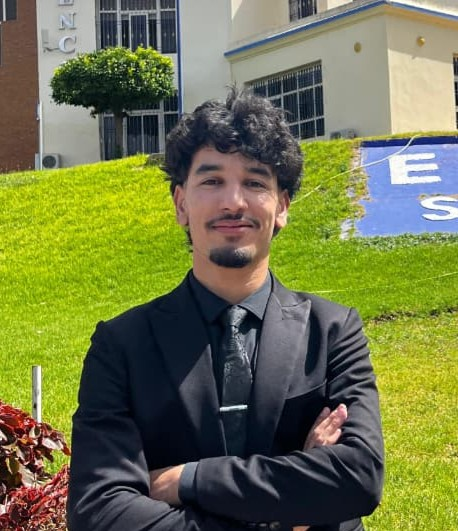

In [39]:
!pip -q install -U scikit-learn xgboost umap-learn gymnasium

In [40]:
# Sources réelles intégrées à scikit-learn : trois problèmes différents
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes, load_breast_cancer, load_wine
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, f1_score, roc_auc_score, silhouette_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
GRAINE = 42

jeu_regression = load_diabetes()
X_reg, y_reg = jeu_regression.data, jeu_regression.target
jeu_classification = load_breast_cancer()
X_cls, y_cls = jeu_classification.data, jeu_classification.target
jeu_non_supervise = load_wine()
X_clu = StandardScaler().fit_transform(jeu_non_supervise.data)  # Exploration sans cible

Xr_ent, Xr_test, yr_ent, yr_test = train_test_split(X_reg, y_reg, test_size=.25, random_state=GRAINE)
Xc_ent, Xc_test, yc_ent, yc_test = train_test_split(X_cls, y_cls, test_size=.25, stratify=y_cls, random_state=GRAINE)
print('Diabetes:', X_reg.shape, '| Breast Cancer:', X_cls.shape, '| Wine:', X_clu.shape)
print('Ces données sont réelles ; les étiquettes du vin ne sont pas employées dans le clustering.')


Diabetes: (442, 10) | Breast Cancer: (569, 30) | Wine: (178, 13)
Ces données sont réelles ; les étiquettes du vin ne sont pas employées dans le clustering.


## 1. Régression linéaire

**Variante C — question spécifique :** Quel diagnostic du résidu indique une mauvaise spécification linéaire ?

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.

### Présentation
Régression supervisée. Entrée : vecteur de caractéristiques x ; sortie : valeur continue ŷ. Hypothèse : relation conditionnelle approximativement linéaire et erreurs de moyenne nulle. Le modèle estime les coefficients par moindres carrés en minimisant la somme des carrés des résidus. Paramètres appris : β₀ et βⱼ. Hyperparamètre : aucun réglage usuel dans LinearRegression ; on peut comparer une contrainte positive ou la sélection de variables, sans confondre cela avec un coefficient.

**Équation et symboles :** ŷᵢ = β₀ + Σⱼ βⱼxᵢⱼ + εᵢ. ŷᵢ : prédiction ; β₀ : intercept ; βⱼ : coefficient appris ; xᵢⱼ : variable j de l'observation i ; εᵢ : erreur.

### Schéma original — mécanisme
```text
Initialisation : matrice X et cible y → apprentissage : minimisation Σ(yᵢ−ŷᵢ)² → sortie : coefficients β et prédictions. Le choix central est la forme linéaire.
```

### Contextes et choix
Prévoir une demande ou un chiffre d'affaires à partir de prix, saison et publicité ; estimer un coût logistique à partir de distance et volume. Concurrent : Ridge. Peu adaptée à des relations fortement non linéaires ou à des observations dépendantes. MAE est lisible en unités métier ; RMSE pénalise davantage les grosses erreurs.

### Test de sensibilité et interprétation
L'expérience doit comparer la configuration de départ à une variante de l'hyperparamètre indiqué dans la question de la section. Utiliser l'ensemble de validation, conserver les valeurs effectivement imprimées, puis commenter le compromis observé. Une seule graine ou un seul découpage ne permet pas de conclure à une supériorité générale. Ne pas inventer de métrique : exécuter les cellules et compléter l'interprétation à partir des sorties.


In [41]:
from sklearn.linear_model import LinearRegression
modele = LinearRegression().fit(Xr_ent, yr_ent)
predictions = modele.predict(Xr_test)
print('MAE régression linéaire :', round(mean_absolute_error(yr_test, predictions), 2))
print('R² :', round(r2_score(yr_test, predictions), 3))

MAE régression linéaire : 41.55
R² : 0.485


## 2. Ridge

**Variante C — question spécifique :** Comment évoluent les coefficients quand alpha augmente ?

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.

### Présentation
Régression supervisée régularisée. Elle reçoit X numérique et y continue, puis renvoie une prédiction continue. Elle suppose une relation linéaire, mais pénalise les coefficients pour limiter leur variance et la colinéarité. Les coefficients sont obtenus par minimisation de l'erreur quadratique plus une pénalité L2. Paramètres appris : coefficients β et intercept. Hyperparamètre : alpha, intensité de la pénalité.

**Équation et symboles :** minβ Σᵢ(yᵢ−β₀−xᵢᵀβ)² + α||β||₂². α≥0 contrôle la régularisation ; ||β||₂² est la somme des carrés des coefficients.

### Schéma original — mécanisme
```text
Initialisation : coefficients → apprentissage : compromis erreur / norme L2 → sortie : coefficients généralement rapprochés de zéro, rarement exactement nuls.
```

### Contextes et choix
Prévision de ventes avec variables marketing corrélées ; estimation de coûts avec indicateurs financiers redondants. Concurrent : Lasso. Moins adaptée si une sélection exacte de variables est recherchée. MAE/RMSE mesurent l'erreur ; comparer aussi la stabilité des coefficients.

### Test de sensibilité et interprétation
L'expérience doit comparer la configuration de départ à une variante de l'hyperparamètre indiqué dans la question de la section. Utiliser l'ensemble de validation, conserver les valeurs effectivement imprimées, puis commenter le compromis observé. Une seule graine ou un seul découpage ne permet pas de conclure à une supériorité générale. Ne pas inventer de métrique : exécuter les cellules et compléter l'interprétation à partir des sorties.


In [42]:
from sklearn.linear_model import Ridge
modele = make_pipeline(StandardScaler(), Ridge(alpha=12.0)).fit(Xr_ent, yr_ent)
print('MAE Ridge :', round(mean_absolute_error(yr_test, modele.predict(Xr_test)), 2))

MAE Ridge : 41.46


## 3. Lasso

**Variante C — question spécifique :** Combien de variables sont annulées pour trois valeurs d’alpha ?

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.

### Présentation
Régression supervisée avec pénalité L1. Entrée : variables numériques ; sortie : valeur continue. Hypothèse : relation approximativement linéaire et solution parcimonieuse plausible. L'algorithme minimise l'erreur quadratique et la somme des valeurs absolues des coefficients. Paramètres appris : β. Hyperparamètre : alpha. Certains coefficients peuvent devenir exactement nuls.

**Équation et symboles :** minβ [Σᵢ(yᵢ−β₀−xᵢᵀβ)² + αΣⱼ|βⱼ|]. α règle la force de sélection ; βⱼ est le coefficient de la variable j.

### Schéma original — mécanisme
```text
Initialisation : coefficients → apprentissage : pénalité L1 pousse certains coefficients à zéro → sortie : prédiction et sous-ensemble de variables retenues.
```

### Contextes et choix
Sélection d'indicateurs de risque financier ; réduction des variables d'une prévision commerciale. Concurrent : Ridge. Peu adapté lorsque plusieurs variables corrélées portent ensemble un signal diffus. MAE/RMSE évaluent la prédiction ; nombre de coefficients non nuls décrit la parcimonie.

### Test de sensibilité et interprétation
L'expérience doit comparer la configuration de départ à une variante de l'hyperparamètre indiqué dans la question de la section. Utiliser l'ensemble de validation, conserver les valeurs effectivement imprimées, puis commenter le compromis observé. Une seule graine ou un seul découpage ne permet pas de conclure à une supériorité générale. Ne pas inventer de métrique : exécuter les cellules et compléter l'interprétation à partir des sorties.


In [43]:
from sklearn.linear_model import Lasso
modele = make_pipeline(StandardScaler(), Lasso(alpha=2.0, max_iter=15000)).fit(Xr_ent, yr_ent)
print('Nombre de coefficients non nuls :', np.count_nonzero(modele[-1].coef_))
print('MAE Lasso :', round(mean_absolute_error(yr_test, modele.predict(Xr_test)), 2))

Nombre de coefficients non nuls : 8
MAE Lasso : 41.37


## 4. Régression polynomiale

**Variante C — question spécifique :** Le degré 2 améliore-t-il le test ou seulement l’entraînement ?

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.

### Présentation
Régression supervisée non linéaire en variables, mais linéaire en coefficients. Les entrées sont transformées en puissances et interactions ; la sortie est continue. Hypothèse : la courbure peut être approchée par un polynôme de degré limité. On crée les caractéristiques polynomiales puis on ajuste une régression, ici Ridge. Paramètres appris : coefficients des termes transformés. Hyperparamètre : degree (et alpha de Ridge).

**Équation et symboles :** ŷ = β₀ + Σₖ βₖ φₖ(x), où φₖ(x) représente une puissance ou interaction construite à partir de x ; βₖ est appris.

### Schéma original — mécanisme
```text
Initialisation : variables d'origine → apprentissage : expansion en x, x², interactions puis ajustement → sortie : courbe polynomiale.
```

### Contextes et choix
Modéliser une courbe de demande selon le prix ; prévoir un coût avec effets non linéaires de distance et volume. Concurrent : arbres/boosting. Peu adaptée aux extrapolations lointaines et aux degrés élevés qui surajustent. MAE/RMSE sur validation et écart train-validation évaluent la généralisation.

### Test de sensibilité et interprétation
L'expérience doit comparer la configuration de départ à une variante de l'hyperparamètre indiqué dans la question de la section. Utiliser l'ensemble de validation, conserver les valeurs effectivement imprimées, puis commenter le compromis observé. Une seule graine ou un seul découpage ne permet pas de conclure à une supériorité générale. Ne pas inventer de métrique : exécuter les cellules et compléter l'interprétation à partir des sorties.


In [44]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge
modele = make_pipeline(StandardScaler(), PolynomialFeatures(degree=2, include_bias=False), Ridge(alpha=100.)).fit(Xr_ent, yr_ent)
print('R² polynomial :', round(r2_score(yr_test, modele.predict(Xr_test)), 3))

R² polynomial : 0.501


## 5. Arbre de régression

**Variante C — question spécifique :** Quel effet de max_depth sur le biais et la variance ?

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.

### Présentation
Régression supervisée par partitionnement. Entrée : observations décrites par variables ; sortie : moyenne de la cible dans la feuille atteinte. Il suppose que des régions de l'espace peuvent être représentées par des constantes. À chaque nœud, il choisit une variable et un seuil réduisant l'erreur quadratique. Paramètres appris : seuils, variables et valeurs des feuilles. Hyperparamètre : max_depth ou min_samples_leaf.

**Équation et symboles :** J(t)=Σᵢ∈t(yᵢ−ȳₜ)². t est un nœud ; ȳₜ la moyenne de la cible dans ce nœud ; le split retenu réduit la somme des erreurs.

### Schéma original — mécanisme
```text
Initialisation : nœud contenant toutes les données → apprentissage : choix récursif de seuils → sortie : règles SI/ALORS et valeur de feuille.
```

### Contextes et choix
Prévoir délais de livraison selon poids et distance ; estimer ventes selon canal et saison. Concurrent : forêt aléatoire. Peu adapté aux extrapolations et aux petits échantillons instables. MAE/RMSE et profondeur facilitent le compromis précision/interprétabilité.

### Test de sensibilité et interprétation
L'expérience doit comparer la configuration de départ à une variante de l'hyperparamètre indiqué dans la question de la section. Utiliser l'ensemble de validation, conserver les valeurs effectivement imprimées, puis commenter le compromis observé. Une seule graine ou un seul découpage ne permet pas de conclure à une supériorité générale. Ne pas inventer de métrique : exécuter les cellules et compléter l'interprétation à partir des sorties.


In [45]:
from sklearn.tree import DecisionTreeRegressor
modele = DecisionTreeRegressor(max_depth=3, min_samples_leaf=8, random_state=GRAINE).fit(Xr_ent, yr_ent)
print('MAE arbre :', round(mean_absolute_error(yr_test, modele.predict(Xr_test)), 2))

MAE arbre : 44.57


## 6. Forêt aléatoire — régression

**Variante C — question spécifique :** La forêt réduit-elle la variance par rapport à l’arbre ?

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.

### Présentation
Ensemble supervisé d'arbres. Chaque arbre est entraîné sur un échantillon bootstrap et un sous-ensemble aléatoire de variables ; la sortie est la moyenne des prédictions. Hypothèse : des arbres diversifiés ont des erreurs partiellement décorrélées. Paramètres appris : structures et valeurs de feuilles de chaque arbre. Hyperparamètres : n_estimators, max_features, max_depth.

**Équation et symboles :** ŷ(x)= (1/B)Σᵦ Tᵦ(x). B est le nombre d'arbres et Tᵦ la prédiction de l'arbre b.

### Schéma original — mécanisme
```text
Initialisation : échantillons bootstrap et variables tirées au hasard → apprentissage : arbres indépendants → sortie : moyenne qui réduit la variance.
```

### Contextes et choix
Prévision de demande multi-facteurs ; estimation de risque de retard en logistique. Concurrent : gradient boosting. Moins adaptée si une extrapolation au-delà des valeurs observées est nécessaire. MAE/RMSE ; comparer la variabilité entre graines ou tailles de forêt.

### Test de sensibilité et interprétation
L'expérience doit comparer la configuration de départ à une variante de l'hyperparamètre indiqué dans la question de la section. Utiliser l'ensemble de validation, conserver les valeurs effectivement imprimées, puis commenter le compromis observé. Une seule graine ou un seul découpage ne permet pas de conclure à une supériorité générale. Ne pas inventer de métrique : exécuter les cellules et compléter l'interprétation à partir des sorties.


In [46]:
from sklearn.ensemble import RandomForestRegressor
modele = RandomForestRegressor(n_estimators=60, max_depth=6, n_jobs=-1, random_state=GRAINE).fit(Xr_ent, yr_ent)
print('MAE forêt :', round(mean_absolute_error(yr_test, modele.predict(Xr_test)), 2))

MAE forêt : 43.11


## 7. Gradient Boosting — régression

**Variante C — question spécifique :** Que change max_iter sur le coût et le risque de surajustement ?

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.

### Présentation
Ensemble supervisé additif d'arbres faibles. Entrée : X, cible continue ; sortie : somme de corrections successives. Il suppose qu'une fonction peut être construite progressivement en suivant le gradient négatif de la perte. Chaque nouvel arbre corrige les résidus/pseudo-résidus. Paramètres appris : arbres et poids de leurs feuilles. Hyperparamètres : max_iter, learning_rate, max_leaf_nodes.

**Équation et symboles :** Fₘ(x)=Fₘ₋₁(x)+ηhₘ(x). Fₘ est le modèle après m étapes ; hₘ l'arbre correcteur ; η le taux d'apprentissage.

### Schéma original — mécanisme
```text
Initialisation : prédiction constante → apprentissage : arbre ajouté pour réduire la perte → sortie : somme séquentielle d'arbres.
```

### Contextes et choix
Prévision de chiffre d'affaires ; estimation du délai de transport. Concurrent : forêt aléatoire. Sensible au bruit et au réglage, moins simple à interpréter. MAE/RMSE sur validation et temps d'entraînement.

### Test de sensibilité et interprétation
L'expérience doit comparer la configuration de départ à une variante de l'hyperparamètre indiqué dans la question de la section. Utiliser l'ensemble de validation, conserver les valeurs effectivement imprimées, puis commenter le compromis observé. Une seule graine ou un seul découpage ne permet pas de conclure à une supériorité générale. Ne pas inventer de métrique : exécuter les cellules et compléter l'interprétation à partir des sorties.


In [47]:
from sklearn.ensemble import HistGradientBoostingRegressor
modele = HistGradientBoostingRegressor(max_iter=100, max_leaf_nodes=9, random_state=GRAINE).fit(Xr_ent, yr_ent)
print('MAE boosting :', round(mean_absolute_error(yr_test, modele.predict(Xr_test)), 2))

MAE boosting : 44.18


## 8. Régression logistique

**Variante C — question spécifique :** Quel effet de C sur les probabilités et la frontière ?

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.

### Présentation
Classification supervisée, malgré son nom. Entrée : variables numériques ; sortie : probabilité de classe puis étiquette. Hypothèse : log-odds linéaires dans les variables. Le modèle calcule un score linéaire, le transforme par sigmoïde et optimise la log-vraisemblance pénalisée. Paramètres appris : coefficients et intercept. Hyperparamètre : C, inverse de la régularisation.

**Équation et symboles :** P(y=1|x)=σ(β₀+xᵀβ), σ(z)=1/(1+e⁻ᶻ). β sont les coefficients ; C contrôle la faiblesse de la pénalité.

### Schéma original — mécanisme
```text
Initialisation : coefficients → apprentissage : optimisation de log-loss → sortie : probabilités et décision selon un seuil.
```

### Contextes et choix
Classer des demandes de crédit à des fins pédagogiques ; prédire la réponse à une campagne marketing. Concurrent : SVM ou forêt. Moins adaptée aux frontières très complexes sans transformations. F1 si classes déséquilibrées ; ROC-AUC pour classer les scores à différents seuils.

### Test de sensibilité et interprétation
L'expérience doit comparer la configuration de départ à une variante de l'hyperparamètre indiqué dans la question de la section. Utiliser l'ensemble de validation, conserver les valeurs effectivement imprimées, puis commenter le compromis observé. Une seule graine ou un seul découpage ne permet pas de conclure à une supériorité générale. Ne pas inventer de métrique : exécuter les cellules et compléter l'interprétation à partir des sorties.


In [48]:
from sklearn.linear_model import LogisticRegression
modele = make_pipeline(StandardScaler(), LogisticRegression(C=.5, max_iter=2000, random_state=GRAINE)).fit(Xc_ent, yc_ent)
print('F1 logistique :', round(f1_score(yc_test, modele.predict(Xc_test)), 3))

F1 logistique : 0.989


## 9. KNN

**Variante C — question spécifique :** Comparez k = 3, 7 et 15 ; quelle métrique varie ?

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.

### Présentation
Classification supervisée fondée sur les voisins. Entrée : vecteurs numériques ; sortie : classe majoritaire ou vote pondéré parmi les k voisins. Hypothèse : observations proches ont souvent la même classe ; l'échelle des variables compte. L'algorithme mémorise les données, calcule les distances et agrège les étiquettes. Paramètre appris : pas de coefficients, la base d'exemples est conservée. Hyperparamètre : n_neighbors et weights.

**Équation et symboles :** ŷ(x)=mode{yᵢ : i∈Nₖ(x)}. Nₖ(x) est l'ensemble des k voisins les plus proches selon la distance choisie.

### Schéma original — mécanisme
```text
Initialisation : base étiquetée → apprentissage : mémorisation → sortie : distance aux voisins et vote.
```

### Contextes et choix
Segmenter des profils clients à partir d'indicateurs ; classer des dossiers selon des cas similaires. Concurrent : SVM. Peu adapté aux grandes dimensions, aux données non standardisées et aux très grands volumes. F1 et matrice de confusion.

### Test de sensibilité et interprétation
L'expérience doit comparer la configuration de départ à une variante de l'hyperparamètre indiqué dans la question de la section. Utiliser l'ensemble de validation, conserver les valeurs effectivement imprimées, puis commenter le compromis observé. Une seule graine ou un seul découpage ne permet pas de conclure à une supériorité générale. Ne pas inventer de métrique : exécuter les cellules et compléter l'interprétation à partir des sorties.


In [49]:
from sklearn.neighbors import KNeighborsClassifier
modele = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=7, weights='distance')).fit(Xc_ent, yc_ent)
print('F1 KNN :', round(f1_score(yc_test, modele.predict(Xc_test)), 3))

F1 KNN : 0.984


## 10. Naive Bayes

**Variante C — question spécifique :** Dans quel cas l’hypothèse d’indépendance devient-elle critique ?

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.

### Présentation
Classification probabiliste supervisée. Entrée : caractéristiques et classes ; sortie : probabilité a posteriori et classe. Hypothèse forte : indépendance conditionnelle des variables sachant la classe ; GaussianNB suppose des distributions gaussiennes par variable. Il estime les a priori et distributions puis applique Bayes. Paramètres appris : moyennes, variances et probabilités a priori. Hyperparamètre : var_smoothing.

**Équation et symboles :** P(C|x) ∝ P(C)∏ⱼP(xⱼ|C). C est la classe ; xⱼ la caractéristique j ; le produit traduit l'indépendance conditionnelle.

### Schéma original — mécanisme
```text
Initialisation : classes possibles → apprentissage : estimation des distributions par classe → sortie : posteriori et classe la plus probable.
```

### Contextes et choix
Filtrage de demandes ou catégorisation rapide de documents vectorisés ; tri initial de profils commerciaux. Concurrent : régression logistique. Moins adapté lorsque les variables sont fortement dépendantes. F1, ROC-AUC et calibration des probabilités.

### Test de sensibilité et interprétation
L'expérience doit comparer la configuration de départ à une variante de l'hyperparamètre indiqué dans la question de la section. Utiliser l'ensemble de validation, conserver les valeurs effectivement imprimées, puis commenter le compromis observé. Une seule graine ou un seul découpage ne permet pas de conclure à une supériorité générale. Ne pas inventer de métrique : exécuter les cellules et compléter l'interprétation à partir des sorties.


In [50]:
from sklearn.naive_bayes import GaussianNB
modele = GaussianNB(var_smoothing=1e-8).fit(Xc_ent, yc_ent)
print('F1 Naive Bayes :', round(f1_score(yc_test, modele.predict(Xc_test)), 3))

F1 Naive Bayes : 0.962


## 11. Arbre de décision

**Variante C — question spécifique :** Quelle variable guide la première séparation de l’arbre ?

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.

### Présentation
Classification supervisée par règles. Entrée : variables ; sortie : classe ou distribution de classes en feuille. Il partitionne les données en réduisant l'impureté (Gini ou entropie). Les splits sont appris récursivement. Paramètres appris : variables, seuils et proportions de classes dans les feuilles. Hyperparamètre : max_depth, min_samples_leaf ou criterion.

**Équation et symboles :** Gini(t)=1−Σₖpₖ², où pₖ est la proportion de la classe k dans le nœud t ; le split minimise l'impureté pondérée des enfants.

### Schéma original — mécanisme
```text
Initialisation : nœud racine → apprentissage : sélection du split qui réduit Gini/entropie → sortie : chemin de règles jusqu'à une feuille.
```

### Contextes et choix
Décision pédagogique de risque client ; tri de demandes selon urgence et caractéristiques. Concurrent : forêt aléatoire. Peu adapté aux frontières lisses et aux petits changements de données. F1, ROC-AUC et matrice de confusion.

### Test de sensibilité et interprétation
L'expérience doit comparer la configuration de départ à une variante de l'hyperparamètre indiqué dans la question de la section. Utiliser l'ensemble de validation, conserver les valeurs effectivement imprimées, puis commenter le compromis observé. Une seule graine ou un seul découpage ne permet pas de conclure à une supériorité générale. Ne pas inventer de métrique : exécuter les cellules et compléter l'interprétation à partir des sorties.


In [51]:
from sklearn.tree import DecisionTreeClassifier
modele = DecisionTreeClassifier(max_depth=3, min_samples_leaf=6, random_state=GRAINE).fit(Xc_ent, yc_ent)
print('F1 arbre :', round(f1_score(yc_test, modele.predict(Xc_test)), 3))

F1 arbre : 0.956


## 12. Forêt aléatoire — classification

**Variante C — question spécifique :** Quel effet du nombre d’arbres sur la stabilité ?

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.

### Présentation
Ensemble supervisé d'arbres de décision entraînés sur bootstrap et sous-ensembles de variables. Chaque arbre vote ; la classe majoritaire est retournée. La diversité des arbres réduit la variance. Paramètres appris : arbres et distributions de classes en feuilles. Hyperparamètres : n_estimators, max_features, max_depth.

**Équation et symboles :** ŷ(x)=mode{T₁(x),…,T_B(x)}. Tᵦ est la classe prédite par l'arbre b ; B le nombre d'arbres.

### Schéma original — mécanisme
```text
Initialisation : bootstrap et variables aléatoires → apprentissage : arbres indépendants → sortie : vote agrégé.
```

### Contextes et choix
Détection pédagogique de défauts de paiement ; classification de retards de livraison. Concurrent : gradient boosting. Moins adaptée si une explication causale simple est attendue. F1, ROC-AUC, matrice de confusion et stabilité entre graines.

### Test de sensibilité et interprétation
L'expérience doit comparer la configuration de départ à une variante de l'hyperparamètre indiqué dans la question de la section. Utiliser l'ensemble de validation, conserver les valeurs effectivement imprimées, puis commenter le compromis observé. Une seule graine ou un seul découpage ne permet pas de conclure à une supériorité générale. Ne pas inventer de métrique : exécuter les cellules et compléter l'interprétation à partir des sorties.


In [52]:
from sklearn.ensemble import RandomForestClassifier
modele = RandomForestClassifier(n_estimators=70, max_features='log2', random_state=GRAINE, n_jobs=-1).fit(Xc_ent, yc_ent)
print('F1 forêt :', round(f1_score(yc_test, modele.predict(Xc_test)), 3))

F1 forêt : 0.967


## 13. SVM

**Variante C — question spécifique :** Comparez noyau linéaire et RBF, et justifiez le choix.

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.

### Présentation
Classification supervisée à marge maximale. Entrée : variables numériques ; sortie : classe et score de décision. Il cherche une frontière séparant les classes avec marge maximale ; noyau RBF permet une frontière non linéaire. Paramètres appris : vecteur de poids et support vectors. Hyperparamètres : C, kernel, gamma.

**Équation et symboles :** f(x)=sign(Σᵢ αᵢyᵢK(xᵢ,x)+b). αᵢ sont les multiplicateurs appris ; yᵢ les étiquettes ; K le noyau ; b le biais.

### Schéma original — mécanisme
```text
Initialisation : choix du noyau → apprentissage : optimisation de marge et pénalisation des erreurs → sortie : frontière et vecteurs de support.
```

### Contextes et choix
Classer des transactions simulées selon attributs ; catégoriser des prospects. Concurrent : régression logistique. Peu adapté aux très grands jeux sans stratégie de mise à l'échelle. Standardiser ; comparer F1 et ROC-AUC.

### Test de sensibilité et interprétation
L'expérience doit comparer la configuration de départ à une variante de l'hyperparamètre indiqué dans la question de la section. Utiliser l'ensemble de validation, conserver les valeurs effectivement imprimées, puis commenter le compromis observé. Une seule graine ou un seul découpage ne permet pas de conclure à une supériorité générale. Ne pas inventer de métrique : exécuter les cellules et compléter l'interprétation à partir des sorties.


In [53]:
from sklearn.svm import SVC
modele = make_pipeline(StandardScaler(), SVC(kernel='linear', C=.2, random_state=GRAINE)).fit(Xc_ent, yc_ent)
print('F1 SVM linéaire :', round(f1_score(yc_test, modele.predict(Xc_test)), 3))

F1 SVM linéaire : 0.989


## 14. Gradient Boosting — classification

**Variante C — question spécifique :** Quel effet du nombre d’itérations sur le temps et F1 ?

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.

### Présentation
Ensemble supervisé d'arbres ajoutés séquentiellement pour réduire une perte de classification. Il construit des corrections selon le gradient négatif de la log-loss. Paramètres appris : arbres et valeurs de feuilles. Hyperparamètres : max_iter, learning_rate, max_leaf_nodes.

**Équation et symboles :** Fₘ(x)=Fₘ₋₁(x)+ηhₘ(x), puis p(y=1|x)=σ(Fₘ(x)). η est le taux d'apprentissage ; hₘ l'arbre ajouté.

### Schéma original — mécanisme
```text
Initialisation : score constant → apprentissage : arbres successifs corrigent les erreurs de la perte → sortie : score/probabilité et classe.
```

### Contextes et choix
Scoring de risque ; prédiction de conversion marketing. Concurrent : forêt aléatoire. Peut surajuster avec trop d'itérations ou des arbres trop complexes. F1, ROC-AUC, matrice de confusion et temps.

### Test de sensibilité et interprétation
L'expérience doit comparer la configuration de départ à une variante de l'hyperparamètre indiqué dans la question de la section. Utiliser l'ensemble de validation, conserver les valeurs effectivement imprimées, puis commenter le compromis observé. Une seule graine ou un seul découpage ne permet pas de conclure à une supériorité générale. Ne pas inventer de métrique : exécuter les cellules et compléter l'interprétation à partir des sorties.


In [54]:
from sklearn.ensemble import HistGradientBoostingClassifier
modele = HistGradientBoostingClassifier(max_iter=65, max_leaf_nodes=8, random_state=GRAINE).fit(Xc_ent, yc_ent)
print('F1 boosting :', round(f1_score(yc_test, modele.predict(Xc_test)), 3))

F1 boosting : 0.967


## 15. AdaBoost

**Variante C — question spécifique :** Que change learning_rate quand n_estimators reste fixe ?

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.

### Présentation
Ensemble supervisé qui combine des apprenants faibles, souvent des souches d'arbres. Il augmente le poids des observations mal classées et combine les votes pondérés. Hypothèse : plusieurs apprenants faibles peuvent former un classifieur performant. Paramètres appris : poids des apprenants et leurs règles. Hyperparamètres : n_estimators et learning_rate.

**Équation et symboles :** F(x)=sign(Σₘαₘhₘ(x)). hₘ est l'apprenant m ; αₘ son poids, calculé selon son erreur ; learning_rate réduit son apport.

### Schéma original — mécanisme
```text
Initialisation : poids égaux des observations → apprentissage : réajustement des poids et ajout de faibles apprenants → sortie : vote pondéré.
```

### Contextes et choix
Prioriser des leads commerciaux ; repérer des dossiers à examiner. Concurrent : gradient boosting. Sensible aux observations aberrantes/bruitées. F1 et ROC-AUC ; comparer le nombre d'estimateurs à taux fixé.

### Test de sensibilité et interprétation
L'expérience doit comparer la configuration de départ à une variante de l'hyperparamètre indiqué dans la question de la section. Utiliser l'ensemble de validation, conserver les valeurs effectivement imprimées, puis commenter le compromis observé. Une seule graine ou un seul découpage ne permet pas de conclure à une supériorité générale. Ne pas inventer de métrique : exécuter les cellules et compléter l'interprétation à partir des sorties.


In [55]:
from sklearn.ensemble import AdaBoostClassifier
modele = AdaBoostClassifier(n_estimators=50, learning_rate=.6, random_state=GRAINE).fit(Xc_ent, yc_ent)
print('F1 AdaBoost :', round(f1_score(yc_test, modele.predict(Xc_test)), 3))

F1 AdaBoost : 0.973


## 16. XGBoost

**Variante C — question spécifique :** Que change max_depth sur la capacité du modèle ?

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.

### Présentation
Gradient boosting optimisé, supervisé, fondé sur des arbres et une fonction objectif régularisée. Il ajoute des arbres pour approximer les gradients et hessiens de la perte. Paramètres appris : structures et poids des feuilles. Hyperparamètres : max_depth, learning_rate, n_estimators, régularisation.

**Équation et symboles :** Obj=Σᵢl(yᵢ,ŷᵢ)+Σₘ[γTₘ+(λ/2)||wₘ||²]. l est la perte ; Tₘ le nombre de feuilles ; wₘ leurs poids ; γ et λ pénalisent la complexité.

### Schéma original — mécanisme
```text
Initialisation : prédiction de base → apprentissage : arbres ajoutés en minimisant perte + régularisation → sortie : score agrégé.
```

### Contextes et choix
Prévision de défauts de livraison ; scoring de conversion. Concurrent : HistGradientBoosting. Moins adapté aux petits jeux très bruités sans réglage rigoureux. F1/ROC-AUC et validation ; documenter version/dépendance XGBoost.

### Test de sensibilité et interprétation
L'expérience doit comparer la configuration de départ à une variante de l'hyperparamètre indiqué dans la question de la section. Utiliser l'ensemble de validation, conserver les valeurs effectivement imprimées, puis commenter le compromis observé. Une seule graine ou un seul découpage ne permet pas de conclure à une supériorité générale. Ne pas inventer de métrique : exécuter les cellules et compléter l'interprétation à partir des sorties.


In [56]:
from xgboost import XGBClassifier
modele = XGBClassifier(n_estimators=65, max_depth=2, learning_rate=.08, random_state=GRAINE, eval_metric='logloss', n_jobs=2).fit(Xc_ent, yc_ent)
print('F1 XGBoost :', round(f1_score(yc_test, modele.predict(Xc_test)), 3))

F1 XGBoost : 0.967


## 17. K-means

**Variante C — question spécifique :** Évaluez k = 2, 3, 4 avec silhouette et inertie.

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.

### Présentation
Clustering non supervisé. Entrée : vecteurs numériques ; sortie : k groupes et centroïdes. Il suppose des groupes compacts, approximativement sphériques, et utilise la distance euclidienne. Alternance affectation au centroïde le plus proche et recalcul des moyennes. Paramètres appris : centroïdes et affectations. Hyperparamètre : n_clusters, n_init.

**Équation et symboles :** J=Σᵢ||xᵢ−μ_{cᵢ}||². xᵢ est l'observation ; μ_{cᵢ} son centroïde ; cᵢ son groupe.

### Schéma original — mécanisme
```text
Initialisation : k centroïdes → apprentissage : affectation par distance puis moyenne des groupes → sortie : clusters/centroïdes.
```

### Contextes et choix
Segmentation de clients par comportements d'achat ; regroupement de références produits selon attributs. Concurrent : clustering hiérarchique. Peu adapté aux formes irrégulières et aux densités très différentes. Silhouette et interprétation métier ; ne pas utiliser les étiquettes Wine pour régler k.

### Test de sensibilité et interprétation
L'expérience doit comparer la configuration de départ à une variante de l'hyperparamètre indiqué dans la question de la section. Utiliser l'ensemble de validation, conserver les valeurs effectivement imprimées, puis commenter le compromis observé. Une seule graine ou un seul découpage ne permet pas de conclure à une supériorité générale. Ne pas inventer de métrique : exécuter les cellules et compléter l'interprétation à partir des sorties.


In [57]:
from sklearn.cluster import KMeans
modele = KMeans(n_clusters=3, n_init=15, random_state=GRAINE).fit(X_clu)
print('Inertie K-means :', round(modele.inertia_, 2))
print('Silhouette :', round(silhouette_score(X_clu, modele.labels_), 3))

Inertie K-means : 1277.93
Silhouette : 0.285


## 18. Classification hiérarchique

**Variante C — question spécifique :** Comparez complete et ward sur les mêmes données.

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.

### Présentation
Clustering non supervisé agglomératif. Entrée : matrice de distances ou variables ; sortie : hiérarchie puis groupes après coupe. Il fusionne successivement les groupes selon un critère de liaison (complete, ward…). Paramètres appris : arbre de fusion. Hyperparamètres : n_clusters, linkage et métrique.

**Équation et symboles :** d(A,B)=max_{a∈A,b∈B}d(a,b) pour complete. A et B sont deux clusters ; d est la distance entre observations.

### Schéma original — mécanisme
```text
Initialisation : chaque observation est un singleton → apprentissage : fusion de paires selon linkage → sortie : dendrogramme/groupes après coupe.
```

### Contextes et choix
Hiérarchie de produits ou de segments clients ; regroupement de fournisseurs selon indicateurs. Concurrent : K-means. Peu adaptée aux très grands jeux et au bruit sans préparation. Silhouette et stabilité ; Ward minimise l'augmentation de variance et requiert la distance euclidienne.

### Test de sensibilité et interprétation
L'expérience doit comparer la configuration de départ à une variante de l'hyperparamètre indiqué dans la question de la section. Utiliser l'ensemble de validation, conserver les valeurs effectivement imprimées, puis commenter le compromis observé. Une seule graine ou un seul découpage ne permet pas de conclure à une supériorité générale. Ne pas inventer de métrique : exécuter les cellules et compléter l'interprétation à partir des sorties.


In [58]:
from sklearn.cluster import AgglomerativeClustering
etiquettes = AgglomerativeClustering(n_clusters=3, linkage='complete').fit_predict(X_clu)
print('Silhouette CHA (complete) :', round(silhouette_score(X_clu, etiquettes), 3))

Silhouette CHA (complete) : 0.204


## 19. DBSCAN

**Variante C — question spécifique :** Expliquez pourquoi eps modifie le nombre de points bruit.

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.

### Présentation
Clustering non supervisé basé sur densité. Entrée : points et distance ; sortie : clusters et bruit (-1). Il identifie les zones denses via eps et min_samples, puis étend les clusters depuis les points cœur. Paramètres appris : appartenance aux clusters et points cœur. Hyperparamètres : eps et min_samples.

**Équation et symboles :** Nε(x)={z:d(x,z)≤ε}. Un point est cœur si |Nε(x)|≥m ; ε=eps et m=min_samples.

### Schéma original — mécanisme
```text
Initialisation : points non visités → apprentissage : voisinages denses étendus → sortie : clusters de forme libre et points bruit.
```

### Contextes et choix
Repérer des zones de concentration de livraisons ; identifier des comportements clients denses et cas atypiques. Concurrent : K-means. Peu adapté aux densités très variables. Silhouette seulement si au moins deux clusters non bruit existent ; rapporter aussi bruit et nombre de groupes.

### Test de sensibilité et interprétation
L'expérience doit comparer la configuration de départ à une variante de l'hyperparamètre indiqué dans la question de la section. Utiliser l'ensemble de validation, conserver les valeurs effectivement imprimées, puis commenter le compromis observé. Une seule graine ou un seul découpage ne permet pas de conclure à une supériorité générale. Ne pas inventer de métrique : exécuter les cellules et compléter l'interprétation à partir des sorties.


In [59]:
from sklearn.cluster import DBSCAN
etiquettes = DBSCAN(eps=2.5, min_samples=4).fit_predict(X_clu)
print('Groupes détectés hors bruit :', len(set(etiquettes) - {-1}))
print('Points considérés comme bruit :', np.sum(etiquettes == -1))

Groupes détectés hors bruit : 1
Points considérés comme bruit : 23


## 20. Mélanges gaussiens

**Variante C — question spécifique :** Comparez covariance_type = full et diag.

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.

### Présentation
Clustering probabiliste non supervisé. Entrée : vecteurs ; sortie : probabilités d'appartenance à des composantes gaussiennes. Il suppose que les données sont issues d'un mélange de distributions gaussiennes. EM alterne responsabilités (E) et estimation des paramètres (M). Paramètres appris : poids, moyennes et covariances. Hyperparamètres : n_components, covariance_type.

**Équation et symboles :** p(x)=ΣₖπₖN(x|μₖ,Σₖ). πₖ est le poids ; μₖ la moyenne ; Σₖ la covariance de la composante k.

### Schéma original — mécanisme
```text
Initialisation : paramètres de composantes → E : probabilités d'appartenance → M : mise à jour poids/moyennes/covariances → sortie : clusters probabilistes.
```

### Contextes et choix
Segmentation probabiliste de clients ; profils de fournisseurs selon mesures continues. Concurrent : K-means. Peu adapté aux distributions très non gaussiennes. Silhouette descriptive et BIC/AIC ; aucune interprétation de classe sans validation externe.

### Test de sensibilité et interprétation
L'expérience doit comparer la configuration de départ à une variante de l'hyperparamètre indiqué dans la question de la section. Utiliser l'ensemble de validation, conserver les valeurs effectivement imprimées, puis commenter le compromis observé. Une seule graine ou un seul découpage ne permet pas de conclure à une supériorité générale. Ne pas inventer de métrique : exécuter les cellules et compléter l'interprétation à partir des sorties.


In [60]:
from sklearn.mixture import GaussianMixture
modele = GaussianMixture(n_components=3, covariance_type='diag', random_state=GRAINE).fit(X_clu)
etiquettes = modele.predict(X_clu)
print('Poids du mélange :', np.round(modele.weights_, 3))
print('Silhouette :', round(silhouette_score(X_clu, etiquettes), 3) if len(set(etiquettes)) > 1 else 'non définie')

Poids du mélange : [0.352 0.287 0.361]
Silhouette : 0.281


## 21. ACP

**Variante C — question spécifique :** Combien de composantes faut-il pour 80 % de variance ?

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.

### Présentation
Réduction linéaire non supervisée. Entrée : variables numériques centrées (et souvent standardisées) ; sortie : composantes orthogonales maximisant la variance. Elle calcule les vecteurs propres de la covariance. Paramètres appris : directions principales et valeurs propres. Hyperparamètre : n_components.

**Équation et symboles :** Z=XW. X est la matrice centrée/standardisée ; W contient les vecteurs propres ; Z est la projection en composantes.

### Schéma original — mécanisme
```text
Initialisation : matrice préparée → apprentissage : directions de variance maximale → sortie : coordonnées réduites et ratios de variance expliquée.
```

### Contextes et choix
Réduire les indicateurs financiers corrélés ; visualiser les caractéristiques de produits. Concurrent : UMAP. Peu adaptée si une structure non linéaire est essentielle. Variance expliquée cumulée ; ajuster ACP sur train uniquement dans un protocole prédictif.

### Test de sensibilité et interprétation
L'expérience doit comparer la configuration de départ à une variante de l'hyperparamètre indiqué dans la question de la section. Utiliser l'ensemble de validation, conserver les valeurs effectivement imprimées, puis commenter le compromis observé. Une seule graine ou un seul découpage ne permet pas de conclure à une supériorité générale. Ne pas inventer de métrique : exécuter les cellules et compléter l'interprétation à partir des sorties.


Variance expliquée par composante : [0.362 0.192 0.111]


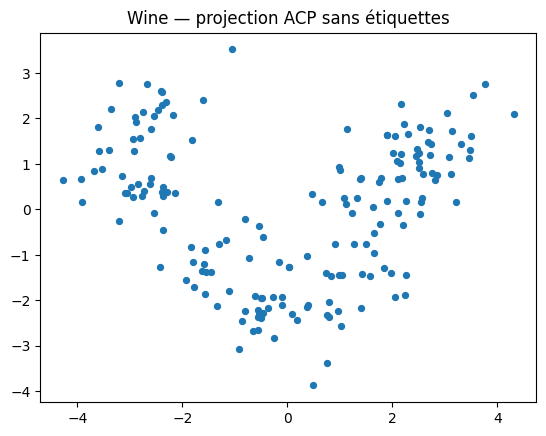

In [61]:
from sklearn.decomposition import PCA
modele = PCA(n_components=3, random_state=GRAINE).fit(X_clu)
projection = modele.transform(X_clu)
print('Variance expliquée par composante :', np.round(modele.explained_variance_ratio_, 3))
plt.scatter(projection[:, 0], projection[:, 1], s=18)
plt.title('Wine — projection ACP sans étiquettes'); plt.show()

## 22. t-SNE

**Variante C — question spécifique :** La structure change-t-elle quand perplexity passe de 12 à 30 ?

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.

### Présentation
Réduction non linéaire surtout destinée à la visualisation. Entrée : vecteurs ; sortie : coordonnées 2D/3D préservant des voisinages probabilistes locaux. Il convertit les distances en probabilités puis minimise une divergence KL entre distributions haute et basse dimensions. Paramètres appris : coordonnées de projection. Hyperparamètre : perplexity, learning_rate, init.

**Équation et symboles :** KL(P||Q)=Σᵢⱼpᵢⱼlog(pᵢⱼ/qᵢⱼ). P décrit les voisinages d'origine ; Q ceux de la carte ; pᵢⱼ et qᵢⱼ sont leurs probabilités.

### Schéma original — mécanisme
```text
Initialisation : projection initiale → apprentissage : déplacement des points pour rapprocher P et Q → sortie : carte 2D ; les distances globales ne sont pas directement interprétables.
```

### Contextes et choix
Explorer des profils clients ; visualiser des familles de produits. Concurrent : UMAP/PCA. Peu adapté comme préprocesseur de prédiction ou pour interpréter les distances entre amas. Examiner stabilité visuelle et voisinages, pas une accuracy.

### Test de sensibilité et interprétation
L'expérience doit comparer la configuration de départ à une variante de l'hyperparamètre indiqué dans la question de la section. Utiliser l'ensemble de validation, conserver les valeurs effectivement imprimées, puis commenter le compromis observé. Une seule graine ou un seul découpage ne permet pas de conclure à une supériorité générale. Ne pas inventer de métrique : exécuter les cellules et compléter l'interprétation à partir des sorties.


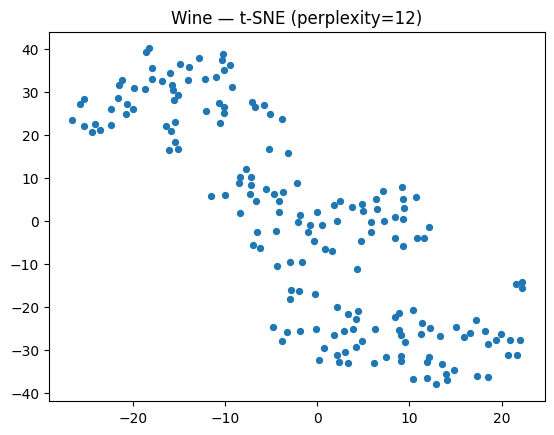

In [62]:
from sklearn.manifold import TSNE
projection = TSNE(n_components=2, perplexity=12, learning_rate='auto', init='pca', random_state=GRAINE).fit_transform(X_clu)
plt.scatter(projection[:, 0], projection[:, 1], s=18)
plt.title('Wine — t-SNE (perplexity=12)'); plt.show()

## 23. UMAP

**Variante C — question spécifique :** Que provoque n_neighbors = 8 puis 30 ?

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.

### Présentation
Réduction non linéaire fondée sur un graphe de voisinage et une représentation topologique. Entrée : vecteurs ; sortie : coordonnées basses dimensions. Il construit un graphe flou de voisinages puis optimise une disposition qui préserve sa structure locale. Paramètres appris : coordonnées de projection. Hyperparamètres : n_neighbors, min_dist, n_components.

**Équation et symboles :** L=Σ_{(i,j)}[wᵢⱼlog(1/qᵢⱼ)+(1−wᵢⱼ)log(1−1/qᵢⱼ)]. wᵢⱼ est le poids du voisinage d'origine ; qᵢⱼ l'affinité dans la carte.

### Schéma original — mécanisme
```text
Initialisation : graphe de voisinage → apprentissage : optimisation des coordonnées → sortie : embedding.
```

### Contextes et choix
Explorer les profils d'acheteurs ; visualiser les similarités entre produits. Concurrent : t-SNE/PCA. Peu adapté à une interprétation causale des axes. Évaluer préservation des voisinages et stabilité selon graines/voisinages.

### Test de sensibilité et interprétation
L'expérience doit comparer la configuration de départ à une variante de l'hyperparamètre indiqué dans la question de la section. Utiliser l'ensemble de validation, conserver les valeurs effectivement imprimées, puis commenter le compromis observé. Une seule graine ou un seul découpage ne permet pas de conclure à une supériorité générale. Ne pas inventer de métrique : exécuter les cellules et compléter l'interprétation à partir des sorties.


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


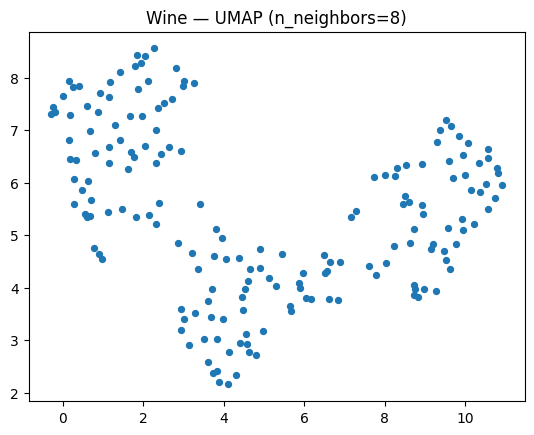

In [63]:
import umap
projection = umap.UMAP(n_components=2, n_neighbors=8, min_dist=.25, random_state=GRAINE).fit_transform(X_clu)
plt.scatter(projection[:, 0], projection[:, 1], s=18)
plt.title('Wine — UMAP (n_neighbors=8)'); plt.show()

## 24. Isolation Forest

**Variante C — question spécifique :** Comparez contamination = 0.03 et 0.10.

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.

### Présentation
Détection non supervisée d'anomalies. Entrée : observations ; sortie : score d'anomalie et indicateur normal/anormal. Il suppose que les anomalies sont rares et isolables en peu de coupures aléatoires. Il construit des arbres d'isolement puis agrège les longueurs de chemin. Paramètres appris : arbres et distributions de chemins. Hyperparamètre : contamination, max_samples, n_estimators.

**Équation et symboles :** s(x)=2^{−E[h(x)]/c(n)}. h(x) est la longueur de chemin ; c(n) la normalisation attendue pour n observations ; score élevé indique une isolation rapide selon la convention de l'algorithme.

### Schéma original — mécanisme
```text
Initialisation : sous-échantillons et arbres → apprentissage : coupures aléatoires → sortie : scores et alertes selon seuil.
```

### Contextes et choix
Repérer des factures atypiques ; signaler des délais logistiques inhabituels. Concurrent : LOF/One-Class SVM. Peu adapté si anomalies nombreuses ou si les anomalies ne sont pas isolables. Sans étiquettes fiables, rapporter uniquement le taux d'alertes et valider humainement.

### Test de sensibilité et interprétation
L'expérience doit comparer la configuration de départ à une variante de l'hyperparamètre indiqué dans la question de la section. Utiliser l'ensemble de validation, conserver les valeurs effectivement imprimées, puis commenter le compromis observé. Une seule graine ou un seul découpage ne permet pas de conclure à une supériorité générale. Ne pas inventer de métrique : exécuter les cellules et compléter l'interprétation à partir des sorties.


In [64]:
from sklearn.ensemble import IsolationForest
modele = IsolationForest(contamination=.07, n_estimators=120, random_state=GRAINE).fit(X_clu)
etiquettes = modele.predict(X_clu)
print('Observations atypiques :', int((etiquettes == -1).sum()))
print('Attention : atypique ne signifie pas erroné ou frauduleux.')

Observations atypiques : 13
Attention : atypique ne signifie pas erroné ou frauduleux.


## 25. Bandits manchots

**Variante C — question spécifique :** Quel bras obtient la meilleure moyenne après 800 tirages ?

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.

### Présentation
Apprentissage par renforcement sans état, problème de décision séquentielle. À chaque tirage, l'agent choisit un bras et reçoit une récompense aléatoire. Il cherche à maximiser la récompense cumulée tout en apprenant les rendements. Paramètres appris : moyennes estimées des bras. Hyperparamètre : horizon de tirages ou règle d'exploration.

**Équation et symboles :** Q̂ₜ(a)=Σ_{s≤t,aₛ=a}rₛ / Nₜ(a). rₛ est la récompense ; Nₜ(a) le nombre de choix du bras a.

### Schéma original — mécanisme
```text
Initialisation : bras et estimations → apprentissage : essais/récompenses → sortie : bras préféré et estimation de rendement.
```

### Contextes et choix
Choisir entre variantes d'une campagne marketing ; tester des mises en avant commerciales. Concurrent : epsilon-greedy/UCB. Peu adapté si les rendements changent rapidement sans modèle contextuel. Comparer récompense moyenne et regret sur plusieurs graines.

### Test de sensibilité et interprétation
L'expérience doit comparer la configuration de départ à une variante de l'hyperparamètre indiqué dans la question de la section. Utiliser l'ensemble de validation, conserver les valeurs effectivement imprimées, puis commenter le compromis observé. Une seule graine ou un seul découpage ne permet pas de conclure à une supériorité générale. Ne pas inventer de métrique : exécuter les cellules et compléter l'interprétation à partir des sorties.


In [65]:
# Bandit pédagogique simulé : estimation des probabilités de gain
rng = np.random.default_rng(GRAINE)
probabilites_simulees = np.array([.35, .55, .65, .45])
recompenses = np.zeros(4); nombre_tirages = np.zeros(4)
for etape in range(800):
    bras = etape % 4
    gain = float(rng.random() < probabilites_simulees[bras])
    recompenses[bras] += gain; nombre_tirages[bras] += 1
print('Récompenses moyennes estimées :', np.round(recompenses / nombre_tirages, 3))

Récompenses moyennes estimées : [0.37 0.53 0.63 0.46]


## 26. Epsilon-greedy

**Variante C — question spécifique :** Quel effet de epsilon sur la concentration des choix ?

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.

### Présentation
Politique d'exploration pour bandit ou RL. Avec probabilité ε, choisit une action aléatoire ; sinon choisit l'action à meilleure valeur estimée. Paramètre appris : valeurs estimées Q̂(a). Hyperparamètre : epsilon (constant ou calendrier).

**Équation et symboles :** P(a)=ε/K+(1−ε)I[a=argmax_b Q̂(b)] (schéma simplifié). K est le nombre de bras ; I vaut 1 si a est greedy.

### Schéma original — mécanisme
```text
Initialisation : valeurs d'action → décision : tirage exploratoire ε ou meilleure action → mise à jour : moyenne/récompense → sortie : fréquences et récompense cumulée.
```

### Contextes et choix
Allouer des impressions entre annonces ; répartir des essais de promotions. Concurrent : UCB/Thompson sampling. Peu adapté si l'exploration uniforme gaspille beaucoup de budget. Récompense moyenne, regret et fréquence de sélection sur plusieurs graines.

### Test de sensibilité et interprétation
L'expérience doit comparer la configuration de départ à une variante de l'hyperparamètre indiqué dans la question de la section. Utiliser l'ensemble de validation, conserver les valeurs effectivement imprimées, puis commenter le compromis observé. Une seule graine ou un seul découpage ne permet pas de conclure à une supériorité générale. Ne pas inventer de métrique : exécuter les cellules et compléter l'interprétation à partir des sorties.


In [66]:
# Exploration epsilon-greedy sur le même bandit simulé
rng = np.random.default_rng(GRAINE)
probabilites_simulees = np.array([.35, .55, .65, .45])
recompenses = np.zeros(4); nombre_tirages = np.zeros(4)
epsilon = .2
for etape in range(1500):
    bras = int(rng.integers(4)) if rng.random() < epsilon or not np.all(nombre_tirages) else int(np.argmax(recompenses / np.maximum(nombre_tirages, 1)))
    gain = float(rng.random() < probabilites_simulees[bras])
    recompenses[bras] += gain; nombre_tirages[bras] += 1
print('Fréquences de sélection :', nombre_tirages.astype(int))
print('Valeurs estimées :', np.round(recompenses / np.maximum(nombre_tirages, 1), 3))

Fréquences de sélection : [  83  119 1215   83]
Valeurs estimées : [0.301 0.504 0.653 0.398]


## 27. Q-learning

**Variante C — question spécifique :** Étudiez les récompenses des épisodes, pas seulement Q moyen.

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.

### Présentation
Renforcement tabulaire hors politique (off-policy). Entrée : état, action, récompense, état suivant ; sortie : politique optimale estimée. Il met à jour Q vers la meilleure action possible dans l'état suivant, même si l'action réellement choisie diffère. Paramètre appris : table Q(s,a). Hyperparamètres : alpha, gamma, epsilon.

**Équation et symboles :** Q(s,a)←Q(s,a)+α[r+γ maxₐ′Q(s′,a′)−Q(s,a)]. α est le taux d'apprentissage ; γ l'actualisation ; r la récompense ; s′ l'état suivant.

### Schéma original — mécanisme
```text
Initialisation : table Q à zéro → interaction epsilon-greedy et mise à jour TD → sortie : politique argmax Q. Dans CliffWalking, le raccourci près de la falaise peut être risqué.
```

### Contextes et choix
Planifier un itinéraire de stock ou de livraison sur grille simplifiée ; optimiser des décisions séquentielles de stock. Concurrent : SARSA. Peu adapté aux états continus sans approximation. Récompense moyenne, longueur d'épisode et fréquence de chute sur plusieurs graines.

### Test de sensibilité et interprétation
L'expérience doit comparer la configuration de départ à une variante de l'hyperparamètre indiqué dans la question de la section. Utiliser l'ensemble de validation, conserver les valeurs effectivement imprimées, puis commenter le compromis observé. Une seule graine ou un seul découpage ne permet pas de conclure à une supériorité générale. Ne pas inventer de métrique : exécuter les cellules et compléter l'interprétation à partir des sorties.


In [67]:
# Q-learning manuel — environnement CliffWalking (Gymnasium)
import gymnasium as gym
env = gym.make('CliffWalking-v1')
q_table = np.zeros((env.observation_space.n, env.action_space.n))
rng = np.random.default_rng(GRAINE)
for episode in range(1100):
    etat, _ = env.reset(seed=GRAINE + episode)
    epsilon = max(.08, .8 * (1 - episode / 900))
    for pas in range(120):
        action = int(rng.integers(env.action_space.n)) if rng.random() < epsilon else int(np.argmax(q_table[etat]))
        suivant, recompense, termine, tronque, _ = env.step(action)
        cible = recompense + (0 if termine else .95 * np.max(q_table[suivant]))
        q_table[etat, action] += .15 * (cible - q_table[etat, action])
        etat = suivant
        if termine or tronque: break
print('Table Q :', q_table.shape, '| valeur moyenne :', round(q_table.mean(), 2))
env.close()

Table Q : (48, 4) | valeur moyenne : -11.22


## 28. SARSA

**Variante C — question spécifique :** SARSA privilégie-t-il une trajectoire plus sûre sous exploration ?

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.

### Présentation
Renforcement tabulaire on-policy. Il met à jour Q avec l'action suivante effectivement choisie par la politique, donc prend en compte l'exploration en cours. Paramètre appris : Q(s,a). Hyperparamètres : alpha, gamma et epsilon. La politique epsilon-greedy détermine à la fois comportement et cible.

**Équation et symboles :** Q(s,a)←Q(s,a)+α[r+γQ(s′,a′)−Q(s,a)]. a′ est l'action réellement choisie au prochain état, contrairement au max de Q-learning.

### Schéma original — mécanisme
```text
Initialisation : table Q → choix action epsilon-greedy → transition et choix de a′ → mise à jour avec Q(s′,a′) → sortie : politique suivie.
```

### Contextes et choix
Navigation d'un robot logistique simplifié ; politique de réapprovisionnement sous exploration. Concurrent : Q-learning. Peu adapté aux espaces d'états/actions immenses sans approximation. Mesurer récompense et épisodes avec chute, plusieurs graines.

### Test de sensibilité et interprétation
L'expérience doit comparer la configuration de départ à une variante de l'hyperparamètre indiqué dans la question de la section. Utiliser l'ensemble de validation, conserver les valeurs effectivement imprimées, puis commenter le compromis observé. Une seule graine ou un seul découpage ne permet pas de conclure à une supériorité générale. Ne pas inventer de métrique : exécuter les cellules et compléter l'interprétation à partir des sorties.


In [68]:
# SARSA manuel — même environnement, politique epsilon-greedy suivie
import gymnasium as gym
env = gym.make('CliffWalking-v1')
q_table = np.zeros((env.observation_space.n, env.action_space.n))
rng = np.random.default_rng(GRAINE)
def choisir_action(etat, epsilon):
    return int(rng.integers(env.action_space.n)) if rng.random() < epsilon else int(np.argmax(q_table[etat]))
for episode in range(1100):
    etat, _ = env.reset(seed=GRAINE + episode)
    epsilon = max(.08, .8 * (1 - episode / 900))
    action = choisir_action(etat, epsilon)
    for pas in range(120):
        suivant, recompense, termine, tronque, _ = env.step(action)
        action_suivante = choisir_action(suivant, epsilon)
        cible = recompense + (0 if termine else .95 * q_table[suivant, action_suivante])
        q_table[etat, action] += .15 * (cible - q_table[etat, action])
        etat, action = suivant, action_suivante
        if termine or tronque: break
print('Table Q SARSA :', q_table.shape, '| valeur moyenne :', round(q_table.mean(), 2))
env.close()

Table Q SARSA : (48, 4) | valeur moyenne : -22.51


## 29. DQN — cible conceptuelle

**Variante C — question spécifique :** Pourquoi la cible est-elle égale à la récompense en état terminal ?

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.

### Présentation
Deep Q-Network est un algorithme de renforcement profond qui approxime Q(s,a) par un réseau neuronal. L'exemple présent calcule seulement la cible de Bellman : il n'entraîne aucun réseau. Paramètres appris dans un vrai DQN : poids du réseau ; hyperparamètres : gamma, taille du replay buffer, learning rate, fréquence de mise à jour cible. Cible terminale égale à r car aucun futur n'est disponible.

**Équation et symboles :** y=r+γ(1−d)maxₐ′Q_target(s′,a′). r est la récompense ; γ l'actualisation ; d=1 si terminal ; Q_target estime la valeur future.

### Schéma original — mécanisme
```text
Initialisation : transition (s,a,r,s′,d) → calcul : si d=1, masque la valeur future → sortie : cible y pour la perte TD. Ici, aucune optimisation de réseau.
```

### Contextes et choix
Contrôle séquentiel de stock simulé ; allocation dynamique de ressources dans un environnement simulé. Concurrent : Q-learning tabulaire. Inadapté aux petits problèmes tabulaires où un réseau est inutile. Sensibilité conceptuelle de gamma/masque terminal ; ne pas prétendre mesurer une performance DQN.

### Test de sensibilité et interprétation
L'expérience doit comparer la configuration de départ à une variante de l'hyperparamètre indiqué dans la question de la section. Utiliser l'ensemble de validation, conserver les valeurs effectivement imprimées, puis commenter le compromis observé. Une seule graine ou un seul découpage ne permet pas de conclure à une supériorité générale. Ne pas inventer de métrique : exécuter les cellules et compléter l'interprétation à partir des sorties.


In [69]:
# Cibles DQN : démonstration du calcul de Bellman, SANS réseau neuronal
recompenses = np.array([-1., -100., 0.])
termine = np.array([False, True, False])
meilleure_valeur_suivante = np.array([-3., -2., 5.])
gamma = .9
cibles = recompenses + gamma * (~termine) * meilleure_valeur_suivante
print('Cibles de Bellman calculées :', np.round(cibles, 2))
print('Ce calcul ne constitue pas un entraînement DQN.')

Cibles de Bellman calculées : [  -3.7 -100.     4.5]
Ce calcul ne constitue pas un entraînement DQN.


## Annexes — implémentations manuelles, variante C

En complément des modèles intégrés : (1) descente de gradient univariée sur une variable réelle de Diabetes, (2) K-means manuel sur la projection ACP de Wine, (3) Q-learning tabulaire manuel dans l'exemple 27. Les modèles manuels sont à comparer aux références scikit-learn **sur les mêmes données**, si une référence existe.


In [70]:
# Descente de gradient manuelle sur Diabetes (une seule caractéristique)
from sklearn.linear_model import LinearRegression
x = Xr_ent[:, 2].copy()  # Indice de masse corporelle, caractéristique déjà centrée dans le jeu
x = (x - x.mean()) / x.std()
y = yr_ent.copy()
poids, biais, taux = 0., 0., .05
for iteration in range(1800):
    erreur = (poids * x + biais) - y
    poids -= taux * 2 * np.mean(erreur * x)
    biais -= taux * 2 * np.mean(erreur)
reference = LinearRegression().fit(x.reshape(-1, 1), y)
print('Manuel :', round(poids, 3), round(biais, 3))
print('scikit-learn :', round(reference.coef_[0], 3), round(reference.intercept_, 3))


Manuel : 45.974 154.344
scikit-learn : 45.974 154.344


In [71]:
# K-means manuel sur projection ACP du jeu Wine (sans étiquettes)
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
valeurs = PCA(n_components=2, random_state=GRAINE).fit_transform(X_clu)
rng = np.random.default_rng(GRAINE)
centroides = valeurs[rng.choice(len(valeurs), size=3, replace=False)].copy()
for iteration in range(100):
    distances = ((valeurs[:, None, :] - centroides[None, :, :]) ** 2).sum(axis=2)
    groupes = distances.argmin(axis=1)
    nouveaux = np.array([valeurs[groupes == k].mean(axis=0) if np.any(groupes == k) else centroides[k] for k in range(3)])
    if np.allclose(nouveaux, centroides):
        break
    centroides = nouveaux
print('Itérations manuelles :', iteration + 1)
print('Inertie manuelle :', round(((valeurs - centroides[groupes]) ** 2).sum(), 2))
modele_reference = KMeans(n_clusters=3, n_init=10, random_state=GRAINE).fit(valeurs)
print('Inertie scikit-learn :', round(modele_reference.inertia_, 2))
# L'inertie peut différer si l'initialisation est différente.


Itérations manuelles : 3
Inertie manuelle : 260.02
Inertie scikit-learn : 259.51


**Q-learning manuel :** réalisé au n°27 dans `CliffWalking-v0`. **SARSA manuel :** réalisé au n°28. `scikit-learn` ne fournit pas d'équivalent tabulaire direct : comparez Q-learning et SARSA avec **la même grille**, plusieurs graines et une politique d'évaluation sans exploration.

## Partie finale — Travail à compléter par le binôme

Créez des cellules supplémentaires : **(a)** tableau de comparaison de tous les algorithmes applicables aux trois jeux réels ; **(b)** au moins cinq figures explicatives ; **(c)** analyse des hyperparamètres ; **(d)** comparaison statistique des agents ; **(e)** conclusion sur les limites, l'éthique et la reproductibilité.

**Variante B non fournie :** les modifications ont été conçues pour différer du fichier A joint ; leur absence de recouvrement avec B ne peut pas être vérifiée.


# Campagne complémentaire C5–C8 — protocole sans fuite

**Important :** les cellules de démonstration précédentes sont conservées. Leurs métriques de test sont descriptives et ne servent pas au réglage. Pour les comparaisons ci-dessous, le jeu d'entraînement est séparé en entraînement/validation ; le test reste isolé jusqu'à l'évaluation finale. La préparation est ajustée uniquement sur l'entraînement.

Les trois bases sont distribuées avec scikit-learn : Diabetes (442 observations, 10 variables, cible quantitative), Breast Cancer Wisconsin Diagnostic (569 observations, 30 variables, cible binaire) et Wine (178 observations, 13 variables numériques, trois catégories connues). Les étiquettes Wine ne sont utilisées ni pour entraîner ni pour régler les méthodes non supervisées. Les bases sont pédagogiques et ne doivent pas être utilisées pour une décision médicale ou commerciale réelle.

Références : [Diabetes — scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_diabetes.html) · [Breast Cancer — scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html) · [Wine — scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_wine.html). Les jeux proviennent de collections historiques intégrées à scikit-learn ; vérifier la documentation de la version installée pour les détails de provenance.

**Limites et éthique :** Breast Cancer contient des mesures médicales et une cible diagnostique historique ; ce n'est pas un outil clinique validé. Diabetes est une cohorte limitée et ancienne ; ses relations ne sont pas causalement interprétables. Wine décrit des échantillons limités à une provenance donnée. Risques : biais d'échantillonnage, faible représentativité externe, fuite de cible et surinterprétation. Les simulations CliffWalking et bandit sont artificielles et ne représentent pas des observations réelles.


In [72]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, f1_score, roc_auc_score, confusion_matrix, classification_report, silhouette_score
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor, RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.cluster import KMeans
import sklearn, sys, time

# Split train/validation/test : le test n'intervient pas dans le choix des hyperparamètres.
Xr_trainval, Xr_test_final, yr_trainval, yr_test_final = train_test_split(X_reg, y_reg, test_size=.20, random_state=GRAINE)
Xr_train, Xr_val, yr_train, yr_val = train_test_split(Xr_trainval, yr_trainval, test_size=.25, random_state=GRAINE)
Xc_trainval, Xc_test_final, yc_trainval, yc_test_final = train_test_split(X_cls, y_cls, test_size=.20, stratify=y_cls, random_state=GRAINE)
Xc_train, Xc_val, yc_train, yc_val = train_test_split(Xc_trainval, yc_trainval, test_size=.25, stratify=yc_trainval, random_state=GRAINE)
print('Python:', sys.version.split()[0], '| scikit-learn:', sklearn.__version__, '| NumPy:', np.__version__, '| pandas:', pd.__version__)
print('Diabetes train/val/test:', Xr_train.shape, Xr_val.shape, Xr_test_final.shape)
print('Cancer train/val/test:', Xc_train.shape, Xc_val.shape, Xc_test_final.shape)
print('Graine fixe:', GRAINE)


Python: 3.13.18 | scikit-learn: 1.9.1 | NumPy: 2.4.6 | pandas: 2.2.3
Diabetes train/val/test: (264, 10) (89, 10) (89, 10)
Cancer train/val/test: (341, 30) (114, 30) (114, 30)
Graine fixe: 42


## C7–C8 — Comparaison des modèles de référence sur validation

Les comparaisons ci-dessous couvrent les tâches supervisées avec trois approches différentes par tâche. Les pipelines ajustent le scaler uniquement sur l'entraînement. Le jeu test final n'est volontairement pas utilisé dans cette étape. Pour les modèles non supervisés, les métriques internes ne remplacent pas l'interprétation métier ; les étiquettes Wine ne sont pas consultées.


,Modèle,MAE,RMSE,R²
1,Ridge,42.630,51.167,0.522
2,Forêt aléatoire,43.977,54.073,0.466
0,Référence moyenne,64.129,75.639,-0.044


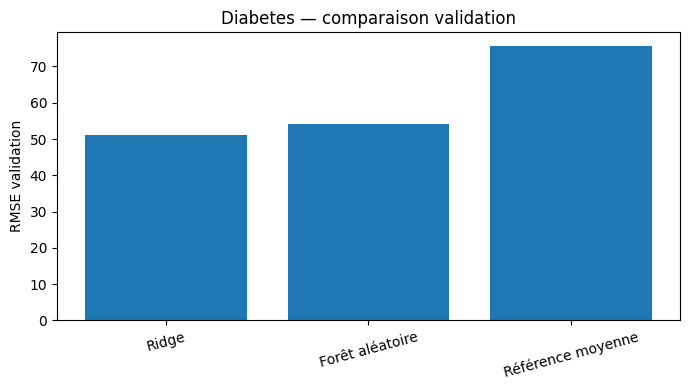

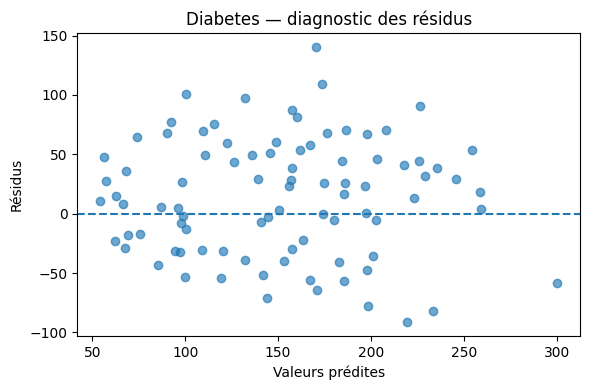

In [73]:
# Régression Diabetes : référence moyenne, Ridge et forêt aléatoire
from sklearn.dummy import DummyRegressor
reg_models = {
    'Référence moyenne': make_pipeline(SimpleImputer(), DummyRegressor(strategy='mean')),
    'Ridge': make_pipeline(SimpleImputer(), StandardScaler(), Ridge(alpha=12.0)),
    'Forêt aléatoire': make_pipeline(SimpleImputer(), RandomForestRegressor(n_estimators=200, min_samples_leaf=3, random_state=GRAINE, n_jobs=-1))
}
rows_reg=[]
for nom, m in reg_models.items():
    m.fit(Xr_train, yr_train)
    pred=m.predict(Xr_val)
    rows_reg.append({'Modèle':nom,'MAE':mean_absolute_error(yr_val,pred),'RMSE':mean_squared_error(yr_val,pred)**0.5,'R²':r2_score(yr_val,pred)})
table_reg=pd.DataFrame(rows_reg).sort_values('RMSE')
display(table_reg.round(3))
plt.figure(figsize=(7,4)); plt.bar(table_reg['Modèle'], table_reg['RMSE']); plt.ylabel('RMSE validation'); plt.title('Diabetes — comparaison validation'); plt.xticks(rotation=15); plt.tight_layout(); plt.show()

# Diagnostic des résidus du meilleur modèle selon RMSE validation
best_reg_name=table_reg.iloc[0]['Modèle']; best_reg=reg_models[best_reg_name]
residus=yr_val-best_reg.predict(Xr_val)
plt.figure(figsize=(6,4)); plt.scatter(best_reg.predict(Xr_val), residus, alpha=.65); plt.axhline(0, linestyle='--'); plt.xlabel('Valeurs prédites'); plt.ylabel('Résidus'); plt.title('Diabetes — diagnostic des résidus'); plt.tight_layout(); plt.show()


,Modèle,F1,ROC-AUC
1,Logistique,0.986,0.998
2,Forêt aléatoire,0.965,0.981
0,Référence majoritaire,0.768,0.500


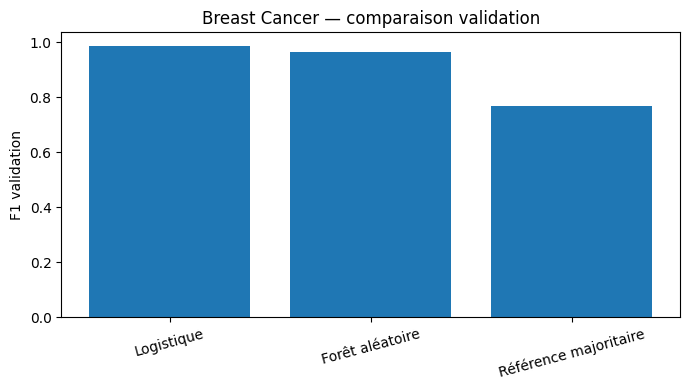

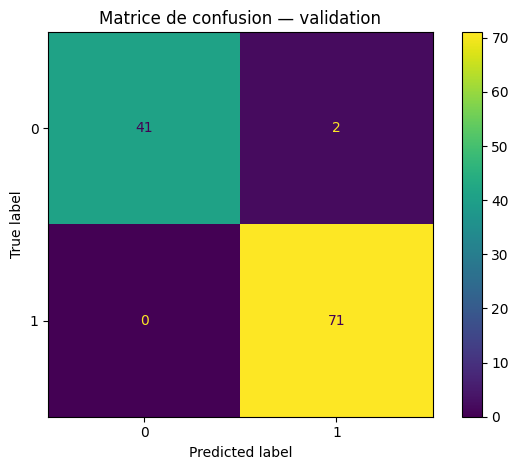

              precision    recall  f1-score   support

   malignant       1.00      0.95      0.98        43
      benign       0.97      1.00      0.99        71

    accuracy                           0.98       114
   macro avg       0.99      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



In [74]:
# Classification Breast Cancer : référence majoritaire, logistique, forêt
from sklearn.dummy import DummyClassifier
from sklearn.metrics import ConfusionMatrixDisplay
cls_models={
    'Référence majoritaire': make_pipeline(SimpleImputer(), DummyClassifier(strategy='most_frequent')),
    'Logistique': make_pipeline(SimpleImputer(), StandardScaler(), LogisticRegression(C=.5, max_iter=3000, random_state=GRAINE)),
    'Forêt aléatoire': make_pipeline(SimpleImputer(), RandomForestClassifier(n_estimators=250, min_samples_leaf=2, random_state=GRAINE, n_jobs=-1))
}
rows_cls=[]
for nom,m in cls_models.items():
    m.fit(Xc_train,yc_train); pred=m.predict(Xc_val)
    proba=m.predict_proba(Xc_val)[:,1] if hasattr(m[-1],'predict_proba') else None
    rows_cls.append({'Modèle':nom,'F1':f1_score(yc_val,pred),'ROC-AUC':roc_auc_score(yc_val,proba) if proba is not None else np.nan})
table_cls=pd.DataFrame(rows_cls).sort_values('F1',ascending=False)
display(table_cls.round(3))
plt.figure(figsize=(7,4)); plt.bar(table_cls['Modèle'], table_cls['F1']); plt.ylabel('F1 validation'); plt.title('Breast Cancer — comparaison validation'); plt.xticks(rotation=15); plt.tight_layout(); plt.show()
best_cls=cls_models[table_cls.iloc[0]['Modèle']]
ConfusionMatrixDisplay.from_predictions(yc_val,best_cls.predict(Xc_val)); plt.title('Matrice de confusion — validation'); plt.tight_layout(); plt.show()
print(classification_report(yc_val,best_cls.predict(Xc_val),target_names=jeu_classification.target_names))


,k,Inertie,Silhouette
0,2,1658.759,0.259
1,3,1277.928,0.285
2,4,1175.352,0.259
3,5,1107.007,0.232


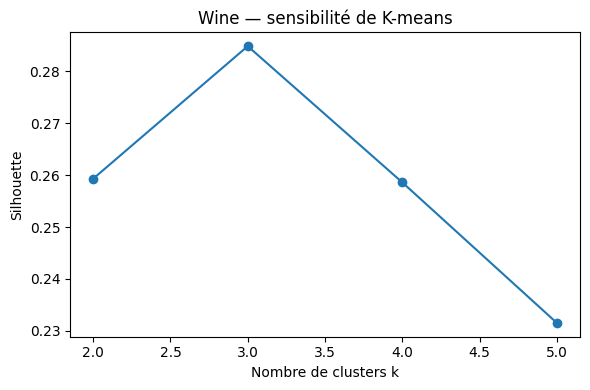

Interprétation : examiner les profils moyens des variables par cluster avant toute étiquette métier. Les labels de cépage/classe ne participent pas au choix de k.


In [75]:
# Clustering Wine : comparaison non supervisée. Les étiquettes ne sont pas utilisées.
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
X_wine_raw=jeu_non_supervise.data
scaler_wine=StandardScaler().fit(X_wine_raw)  # analyse descriptive complète, pas de cible supervisée
X_wine_scaled=scaler_wine.transform(X_wine_raw)
rows_clu=[]
for k in (2,3,4,5):
    km=KMeans(n_clusters=k,n_init=20,random_state=GRAINE).fit(X_wine_scaled)
    rows_clu.append({'k':k,'Inertie':km.inertia_,'Silhouette':silhouette_score(X_wine_scaled,km.labels_)})
table_clu=pd.DataFrame(rows_clu); display(table_clu.round(3))
plt.figure(figsize=(6,4)); plt.plot(table_clu['k'],table_clu['Silhouette'],marker='o'); plt.xlabel('Nombre de clusters k'); plt.ylabel('Silhouette'); plt.title('Wine — sensibilité de K-means'); plt.tight_layout(); plt.show()
print('Interprétation : examiner les profils moyens des variables par cluster avant toute étiquette métier. Les labels de cépage/classe ne participent pas au choix de k.')


## Réduction de dimension et détection d'anomalies — restitution

Pour l'ACP, rapporter la variance expliquée cumulée et choisir le nombre de composantes selon un seuil préétabli (par exemple 80 %), sans utiliser une cible. Pour t-SNE et UMAP, comparer les voisinages préservés et la stabilité des cartes ; les axes et distances entre groupes ne sont pas des mesures absolues. Pour Isolation Forest, le nombre d'alertes dépend notamment de `contamination` : sans étiquettes d'anomalies fiables, il est impossible de calculer une précision/rappel défendable. Les alertes doivent être vérifiées par un expert.


Nombre de composantes pour atteindre 80 % : 5


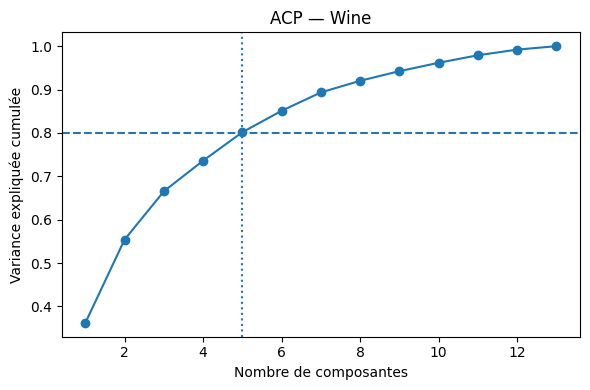

contamination=0.03 : 6 alertes sur 178 observations
contamination=0.10 : 18 alertes sur 178 observations


In [76]:
# ACP : nombre minimal de composantes atteignant 80 % de variance sur Wine
from sklearn.decomposition import PCA
pca_full=PCA().fit(X_wine_scaled)
cum_var=np.cumsum(pca_full.explained_variance_ratio_)
n_80=int(np.argmax(cum_var>=.80)+1)
print('Nombre de composantes pour atteindre 80 % :',n_80)
plt.figure(figsize=(6,4)); plt.plot(np.arange(1,len(cum_var)+1),cum_var,marker='o'); plt.axhline(.80,linestyle='--'); plt.axvline(n_80,linestyle=':'); plt.xlabel('Nombre de composantes'); plt.ylabel('Variance expliquée cumulée'); plt.title('ACP — Wine'); plt.tight_layout(); plt.show()

# Isolation Forest : taux d'alertes pour deux valeurs, sans prétendre à une précision
from sklearn.ensemble import IsolationForest
for contamination in (.03,.10):
    iso=IsolationForest(contamination=contamination,n_estimators=200,random_state=GRAINE).fit(X_wine_scaled)
    alertes=int((iso.predict(X_wine_scaled)==-1).sum())
    print(f'contamination={contamination:.2f} : {alertes} alertes sur {len(X_wine_scaled)} observations')


## Renforcement — comparaison multi-graines et limites

Les expériences de bandit et CliffWalking sont des simulations, pas des données réelles. Le code ci-dessous compare epsilon-greedy sur plusieurs graines dans le bandit à quatre bras défini dans le notebook. Pour Q-learning/SARSA, rapporter récompense moyenne, écart-type, épisodes tronqués et chutes sur plusieurs graines ; la politique doit être évaluée séparément sans exploration. Le code d'origine ne journalise pas ces diagnostics, donc une table Q moyenne seule ne suffit pas à conclure sur la sécurité d'une trajectoire.


,mean,std
epsilon,,
0.05,0.610,0.032
0.20,0.611,0.012
0.40,0.576,0.014


<Figure size 600x400 with 0 Axes>

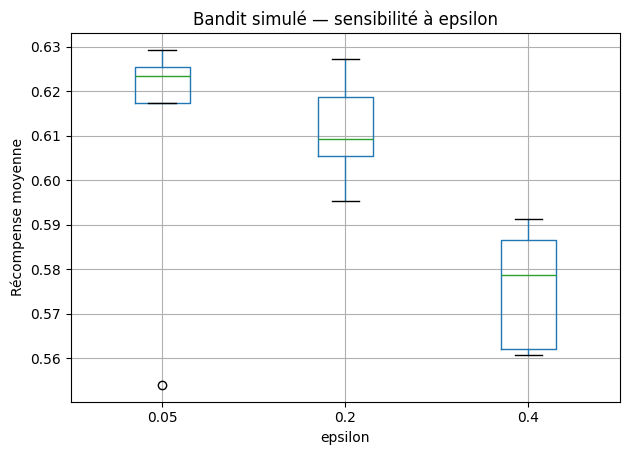

Probabilités simulées des bras : [0.35 0.55 0.65 0.45] ; bras théoriquement le plus rémunérateur : 2


In [77]:
# Bandit simulé : comparaison epsilon sur plusieurs graines et même horizon
probs=np.array([.35,.55,.65,.45]); horizon=1500; resultats=[]
for seed in (7,21,42,84,126):
    for eps in (.05,.20,.40):
        rng_local=np.random.default_rng(seed); counts=np.zeros(4); sums=np.zeros(4); total=0
        for t in range(horizon):
            if rng_local.random()<eps or counts.sum()==0: a=int(rng_local.integers(4))
            else: a=int(np.argmax(sums/np.maximum(counts,1)))
            r=float(rng_local.random()<probs[a]); counts[a]+=1; sums[a]+=r; total+=r
        resultats.append({'Graine':seed,'epsilon':eps,'Récompense moyenne':total/horizon,'Sélections':counts.astype(int).tolist()})
bandit_df=pd.DataFrame(resultats); display(bandit_df.groupby('epsilon')['Récompense moyenne'].agg(['mean','std']).round(3))
plt.figure(figsize=(6,4)); bandit_df.boxplot(column='Récompense moyenne',by='epsilon'); plt.suptitle(''); plt.title('Bandit simulé — sensibilité à epsilon'); plt.ylabel('Récompense moyenne'); plt.tight_layout(); plt.show()

# Pour le rapport : la graine, le nombre de tirages et les probabilités des bras sont simulés.
print('Probabilités simulées des bras :',probs,'; bras théoriquement le plus rémunérateur :',int(np.argmax(probs)))


## Évaluation finale et bilan à compléter après exécution

Une fois les modèles et réglages choisis exclusivement sur validation, réentraîner chaque modèle retenu sur train+validation puis évaluer une seule fois sur test final. Ne pas revenir régler les hyperparamètres à partir de ce résultat.

**Interprétation des résultats observés :**
- Régression : commenter MAE, RMSE, R² et forme des résidus ; signaler les observations influentes et les limites du jeu Diabetes.
- Classification : commenter F1, ROC-AUC, matrice de confusion et erreurs par classe ; rappeler que les étiquettes Breast Cancer ne constituent pas une validation clinique.
- Clustering : expliquer le choix de k avec silhouette/inertie et profils de variables ; si les groupes n'ont pas de sens stable, l'indiquer.
- Réduction : rapporter la variance ACP et rappeler que t-SNE/UMAP sont surtout exploratoires.
- Anomalies : donner le nombre d'alertes, mais ne pas les qualifier de fraude sans labels fiables.
- Renforcement : comparer moyenne et dispersion sur plusieurs graines/épisodes ; différencier récompense, sécurité et exploration.

**Bilan des limites :** échantillons de taille limitée, représentativité historique, hyperparamètres sensibles, hasard d'initialisation, choix de métrique, absence de validation externe et simulations artificielles. Les écarts observés ne prouvent ni causalité ni supériorité universelle.

**À personnaliser avant remise :** compléter les champs d'identification, exécuter toutes les cellules dans l'ordre, conserver les sorties réelles, rédiger vos propres interprétations à partir des chiffres et vérifier que vous pouvez expliquer oralement chaque choix. Les schémas textuels fournis sont des bases à redessiner personnellement si l'enseignant exige des dessins manuscrits/originaux.


## C4 — Tableau de sensibilité des hyperparamètres (validation uniquement)

Cette cellule complète les tests de sensibilité des 29 sections. Les modèles supervisés sont ajustés sur train et évalués sur validation ; les données de test ne sont pas consultées. Les temps et scores sont calculés à l'exécution. Les familles non supervisées sont évaluées avec leurs métriques propres, qui ne sont pas comparables aux scores de classification/régression.


,Expérience,MAE_val,RMSE_val,R2_val,Temps_s
0,Linéaire,42.939,51.194,0.522,0.005
1,Ridge alpha=0.1,42.906,51.174,0.522,0.005
2,Ridge alpha=12.0,42.630,51.167,0.522,0.004
3,Ridge alpha=100.0,43.432,51.737,0.511,0.004
4,Lasso alpha=0.1,42.642,51.100,0.523,0.005
5,Lasso alpha=2.0,42.451,51.034,0.525,0.004
6,Lasso alpha=10.0,45.145,53.151,0.484,0.005
7,Polynôme degré=1,43.432,51.737,0.511,0.006
8,Polynôme degré=2,44.462,54.245,0.463,0.012
9,Polynôme degré=3,50.348,63.739,0.258,0.033


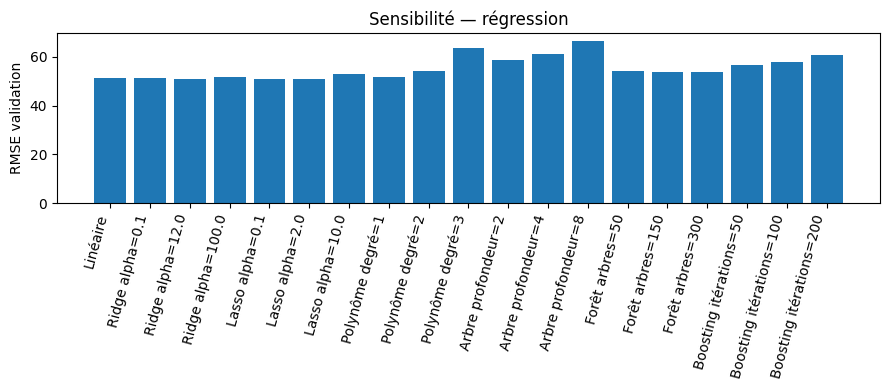

In [78]:
# Sensibilité — régression (Diabetes), toutes les variantes évaluées sur validation
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import PolynomialFeatures
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
reg_sens=[]
def eval_reg(label, estimator):
    start=time.perf_counter(); estimator.fit(Xr_train,yr_train); pred=estimator.predict(Xr_val); elapsed=time.perf_counter()-start
    reg_sens.append({'Expérience':label,'MAE_val':mean_absolute_error(yr_val,pred),'RMSE_val':mean_squared_error(yr_val,pred)**.5,'R2_val':r2_score(yr_val,pred),'Temps_s':elapsed})
eval_reg('Linéaire',make_pipeline(StandardScaler(),LinearRegression()))
for a in (.1,12.,100.): eval_reg(f'Ridge alpha={a}',make_pipeline(StandardScaler(),Ridge(alpha=a)))
for a in (.1,2.,10.): eval_reg(f'Lasso alpha={a}',make_pipeline(StandardScaler(),Lasso(alpha=a,max_iter=20000)))
for d in (1,2,3): eval_reg(f'Polynôme degré={d}',make_pipeline(StandardScaler(),PolynomialFeatures(degree=d,include_bias=False),Ridge(alpha=100.)))
for d in (2,4,8): eval_reg(f'Arbre profondeur={d}',DecisionTreeRegressor(max_depth=d,min_samples_leaf=5,random_state=GRAINE))
for n in (50,150,300): eval_reg(f'Forêt arbres={n}',RandomForestRegressor(n_estimators=n,min_samples_leaf=3,random_state=GRAINE,n_jobs=-1))
for it in (50,100,200): eval_reg(f'Boosting itérations={it}',HistGradientBoostingRegressor(max_iter=it,max_leaf_nodes=9,random_state=GRAINE))
table_reg_sens=pd.DataFrame(reg_sens); display(table_reg_sens.round(3))
plt.figure(figsize=(9,4)); plt.bar(table_reg_sens['Expérience'],table_reg_sens['RMSE_val']); plt.xticks(rotation=75,ha='right'); plt.ylabel('RMSE validation'); plt.title('Sensibilité — régression'); plt.tight_layout(); plt.show()


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,Expérience,F1_val,ROC_AUC_val,Temps_s
0,Logistique C=0.1,0.979,0.997,0.024
1,Logistique C=0.5,0.986,0.998,0.013
2,Logistique C=2.0,0.979,0.998,0.018
3,KNN k=3,0.973,0.985,0.005
4,KNN k=7,0.966,0.995,0.012
5,KNN k=15,0.953,0.995,0.016
6,GaussianNB smoothing=1e-10,0.944,0.987,0.003
7,GaussianNB smoothing=1e-08,0.951,0.988,0.006
8,GaussianNB smoothing=1e-06,0.965,0.985,0.003
9,Arbre profondeur=2,0.958,0.950,0.005


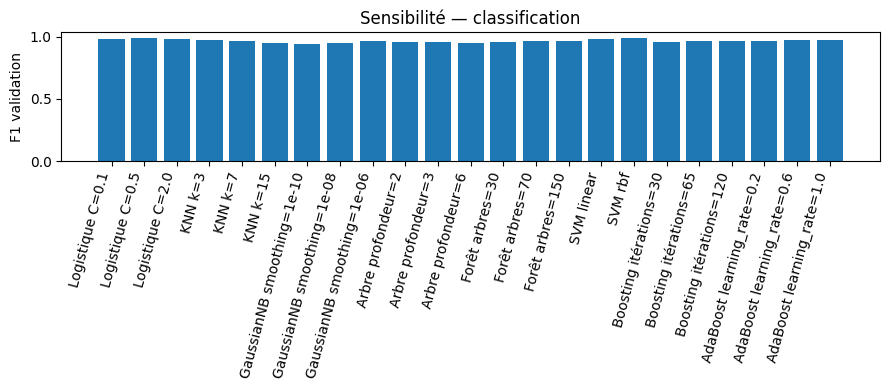

,Expérience,F1_val,ROC_AUC_val,Temps_s
0,XGBoost profondeur=2,0.972,0.991,0.151
1,XGBoost profondeur=3,0.951,0.988,0.248
2,XGBoost profondeur=5,0.958,0.987,0.546


In [79]:
# Sensibilité — classification (Breast Cancer), mêmes splits et métrique F1 validation
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, AdaBoostClassifier
from sklearn.svm import SVC
cls_sens=[]
def eval_cls(label, estimator):
    start=time.perf_counter(); estimator.fit(Xc_train,yc_train); pred=estimator.predict(Xc_val); elapsed=time.perf_counter()-start
    score=estimator.predict_proba(Xc_val)[:,1] if hasattr(estimator,'predict_proba') else estimator.decision_function(Xc_val)
    cls_sens.append({'Expérience':label,'F1_val':f1_score(yc_val,pred),'ROC_AUC_val':roc_auc_score(yc_val,score),'Temps_s':elapsed})
for C in (.1,.5,2.): eval_cls(f'Logistique C={C}',make_pipeline(StandardScaler(),LogisticRegression(C=C,max_iter=3000,random_state=GRAINE)))
for k in (3,7,15): eval_cls(f'KNN k={k}',make_pipeline(StandardScaler(),KNeighborsClassifier(n_neighbors=k,weights='distance')))
for v in (1e-10,1e-8,1e-6): eval_cls(f'GaussianNB smoothing={v}',GaussianNB(var_smoothing=v))
for d in (2,3,6): eval_cls(f'Arbre profondeur={d}',DecisionTreeClassifier(max_depth=d,min_samples_leaf=6,random_state=GRAINE))
for n in (30,70,150): eval_cls(f'Forêt arbres={n}',RandomForestClassifier(n_estimators=n,max_features='log2',random_state=GRAINE,n_jobs=-1))
for kernel in ('linear','rbf'): eval_cls(f'SVM {kernel}',make_pipeline(StandardScaler(),SVC(kernel=kernel,C=.5,probability=True,random_state=GRAINE)))
for it in (30,65,120): eval_cls(f'Boosting itérations={it}',HistGradientBoostingClassifier(max_iter=it,max_leaf_nodes=8,random_state=GRAINE))
for lr in (.2,.6,1.): eval_cls(f'AdaBoost learning_rate={lr}',AdaBoostClassifier(n_estimators=50,learning_rate=lr,random_state=GRAINE))
table_cls_sens=pd.DataFrame(cls_sens); display(table_cls_sens.round(3))
plt.figure(figsize=(9,4)); plt.bar(table_cls_sens['Expérience'],table_cls_sens['F1_val']); plt.xticks(rotation=75,ha='right'); plt.ylabel('F1 validation'); plt.title('Sensibilité — classification'); plt.tight_layout(); plt.show()
# XGBoost (algorithme 16) : cellule facultative si le paquet est disponible.
try:
    from xgboost import XGBClassifier
    for depth in (2,3,5): eval_cls(f'XGBoost profondeur={depth}',XGBClassifier(n_estimators=65,max_depth=depth,learning_rate=.08,random_state=GRAINE,eval_metric='logloss',n_jobs=2))
    display(pd.DataFrame([r for r in cls_sens if 'XGBoost' in r['Expérience']]).round(3))
except ImportError:
    print('XGBoost indisponible : installer xgboost pour exécuter la sensibilité de l’algorithme 16.')


In [80]:
# Sensibilité — clustering, réduction et anomalies sur Wine (sans utiliser les étiquettes)
from sklearn.cluster import AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.ensemble import IsolationForest
clu_rows=[]
for k in (2,3,4):
    m=KMeans(n_clusters=k,n_init=15,random_state=GRAINE).fit(X_wine_scaled)
    clu_rows.append({'Méthode':f'KMeans k={k}','Groupes':len(set(m.labels_)),'Bruit':0,'Silhouette':silhouette_score(X_wine_scaled,m.labels_)})
for link in ('complete','ward'):
    lab=AgglomerativeClustering(n_clusters=3,linkage=link).fit_predict(X_wine_scaled)
    clu_rows.append({'Méthode':f'Hiérarchique {link}','Groupes':len(set(lab)),'Bruit':0,'Silhouette':silhouette_score(X_wine_scaled,lab)})
for eps in (1.5,2.5,3.5):
    lab=DBSCAN(eps=eps,min_samples=4).fit_predict(X_wine_scaled); ncl=len(set(lab)-{-1}); mask=lab!=-1
    sil=silhouette_score(X_wine_scaled[mask],lab[mask]) if ncl>=2 and mask.sum()>ncl else np.nan
    clu_rows.append({'Méthode':f'DBSCAN eps={eps}','Groupes':ncl,'Bruit':int((lab==-1).sum()),'Silhouette':sil})
for cov in ('full','diag'):
    gm=GaussianMixture(n_components=3,covariance_type=cov,random_state=GRAINE).fit(X_wine_scaled); lab=gm.predict(X_wine_scaled)
    clu_rows.append({'Méthode':f'GMM {cov}','Groupes':len(set(lab)),'Bruit':0,'Silhouette':silhouette_score(X_wine_scaled,lab)})
display(pd.DataFrame(clu_rows).round(3))
for n in (2,3,5,8):
    p=PCA(n_components=n,random_state=GRAINE).fit(X_wine_scaled)
    print(f'ACP n_components={n} : variance cumulée={p.explained_variance_ratio_.sum():.3f}')
for contamination in (.03,.07,.10):
    iso=IsolationForest(contamination=contamination,n_estimators=120,random_state=GRAINE).fit(X_wine_scaled)
    print(f'Isolation Forest contamination={contamination}: alertes={(iso.predict(X_wine_scaled)==-1).sum()}')
# t-SNE : comparaison de perplexity ; coordonnées non comparables directement d'une exécution à l'autre.
for perp in (12,30):
    z=TSNE(n_components=2,perplexity=perp,learning_rate='auto',init='pca',random_state=GRAINE).fit_transform(X_wine_scaled)
    print(f't-SNE perplexity={perp}: coordonnées calculées, étendue={np.round(np.ptp(z,axis=0),2)}')
# UMAP facultatif : comparer n_neighbors si umap-learn est installé.
try:
    import umap
    for nn in (8,30):
        z=umap.UMAP(n_components=2,n_neighbors=nn,min_dist=.25,random_state=GRAINE).fit_transform(X_wine_scaled)
        print(f'UMAP n_neighbors={nn}: coordonnées calculées, étendue={np.round(np.ptp(z,axis=0),2)}')
except ImportError:
    print('UMAP indisponible : installer umap-learn pour la sensibilité de l’algorithme 23.')


,Méthode,Groupes,Bruit,Silhouette
0,KMeans k=2,2,0,0.259
1,KMeans k=3,3,0,0.285
2,KMeans k=4,4,0,0.259
3,Hiérarchique complete,3,0,0.204
4,Hiérarchique ward,3,0,0.277
5,DBSCAN eps=1.5,2,169,0.407
6,DBSCAN eps=2.5,1,23,NaN
7,DBSCAN eps=3.5,1,6,NaN
8,GMM full,3,0,0.285
9,GMM diag,3,0,0.281


ACP n_components=2 : variance cumulée=0.554
ACP n_components=3 : variance cumulée=0.665
ACP n_components=5 : variance cumulée=0.802
ACP n_components=8 : variance cumulée=0.920
Isolation Forest contamination=0.03: alertes=6
Isolation Forest contamination=0.07: alertes=13
Isolation Forest contamination=0.1: alertes=18
t-SNE perplexity=12: coordonnées calculées, étendue=[48.98 78.13]
t-SNE perplexity=30: coordonnées calculées, étendue=[24.43 22.48]


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP n_neighbors=8: coordonnées calculées, étendue=[11.21  6.41]


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP n_neighbors=30: coordonnées calculées, étendue=[5.11 9.61]


### Algorithmes 25–29 : réglages et interprétation

Pour le bandit, la comparaison multi-graines de `epsilon` est fournie plus haut ; les fréquences de sélection et la récompense moyenne répondent à C4. Pour CliffWalking, Q-learning et SARSA doivent être évalués sur plusieurs graines avec la même grille, en relevant les récompenses par épisode, la longueur de trajet et les chutes. DQN reste une démonstration de cible et ne possède aucune métrique d'entraînement dans ce notebook.


In [81]:
# Sensibilité conceptuelle DQN : effet de gamma et du masque terminal (pas de réseau entraîné)
rewards=np.array([-1.,-100.,0.]); terminal=np.array([False,True,False]); next_q=np.array([-3.,-2.,5.])
for gamma_test in (.5,.9,.99):
    targets=rewards+gamma_test*(~terminal)*next_q
    print(f'gamma={gamma_test}: cibles={np.round(targets,2)} ; cible terminale={targets[1]:.2f}')
print('Dans tous les cas, l’état terminal masque la valeur future : y=r.')


gamma=0.5: cibles=[  -2.5 -100.     2.5] ; cible terminale=-100.00
gamma=0.9: cibles=[  -3.7 -100.     4.5] ; cible terminale=-100.00
gamma=0.99: cibles=[  -3.97 -100.      4.95] ; cible terminale=-100.00
Dans tous les cas, l’état terminal masque la valeur future : y=r.


In [83]:
# CliffWalking : Q-learning vs SARSA sur plusieurs graines (simulation, pas données réelles)
try:
    import gymnasium as gym
    rl_rows=[]
    for method in ('Q-learning','SARSA'):
        for seed in (7,21,42):
            env_rl=gym.make('CliffWalking-v1'); rng_rl=np.random.default_rng(seed)
            Q=np.zeros((env_rl.observation_space.n,env_rl.action_space.n))
            alpha_rl=.15; gamma_rl=.95; n_episodes=500
            for ep in range(n_episodes):
                state,_=env_rl.reset(seed=seed+ep); eps=max(.08,.8*(1-ep/400))
                if method=='SARSA':
                    action=int(rng_rl.integers(env_rl.action_space.n)) if rng_rl.random()<eps else int(np.argmax(Q[state]))
                for step in range(120):
                    if method=='Q-learning': action=int(rng_rl.integers(env_rl.action_space.n)) if rng_rl.random()<eps else int(np.argmax(Q[state]))
                    nxt,reward,terminated,truncated,_=env_rl.step(action)
                    if method=='Q-learning': target=reward+(0 if terminated else gamma_rl*np.max(Q[nxt]))
                    else:
                        next_action=int(rng_rl.integers(env_rl.action_space.n)) if rng_rl.random()<eps else int(np.argmax(Q[nxt]))
                        target=reward+(0 if terminated else gamma_rl*Q[nxt,next_action])
                    Q[state,action]+=alpha_rl*(target-Q[state,action]); state=nxt
                    if method=='SARSA': action=next_action
                    if terminated or truncated: break
            # Politique greedy d'évaluation : aucun epsilon, plusieurs épisodes indépendants.
            eval_rewards=[]; eval_steps=[]; eval_falls=[]
            for e in range(30):
                state,_=env_rl.reset(seed=10000+seed*100+e); total=0; fell=False
                for step in range(120):
                    action=int(np.argmax(Q[state])); nxt,reward,terminated,truncated,info=env_rl.step(action)
                    total+=reward; fell=fell or (reward==-100); state=nxt
                    if terminated or truncated: break
                eval_rewards.append(total); eval_steps.append(step+1); eval_falls.append(fell)
            rl_rows.append({'Algorithme':method,'Graine':seed,'Récompense moyenne test':np.mean(eval_rewards),'Écart-type récompense':np.std(eval_rewards),'Pas moyens':np.mean(eval_steps),'Épisodes avec chute':int(np.sum(eval_falls))})
            env_rl.close()
    rl_df=pd.DataFrame(rl_rows); display(rl_df.round(2))
    display(rl_df.groupby('Algorithme')[['Récompense moyenne test','Écart-type récompense','Pas moyens','Épisodes avec chute']].agg(['mean','std']).round(2))
except ImportError:
    print('Gymnasium indisponible : installer gymnasium pour comparer Q-learning et SARSA sur CliffWalking-v1.')

,Algorithme,Graine,Récompense moyenne test,Écart-type récompense,Pas moyens,Épisodes avec chute
0,Q-learning,7,-13.0,0.0,13.0,0
1,Q-learning,21,-13.0,0.0,13.0,0
2,Q-learning,42,-13.0,0.0,13.0,0
3,SARSA,7,-17.0,0.0,17.0,0
4,SARSA,21,-17.0,0.0,17.0,0
5,SARSA,42,-17.0,0.0,17.0,0


Récompense moyenne test      Écart-type récompense      Pas moyens  \
                              mean  std                  mean  std       mean   
Algorithme                                                                      
Q-learning                   -13.0  0.0                   0.0  0.0       13.0   
SARSA                        -17.0  0.0                   0.0  0.0       17.0   

                Épisodes avec chute       
            std                mean  std  
Algorithme                                
Q-learning  0.0                 0.0  0.0  
SARSA       0.0                 0.0  0.0